### Train/Test EDA - House Prices

In [92]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
import seaborn as sns
from phik import phik_matrix
import numpy as np

In [93]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
train = train.drop(columns=['Id'])
test = test.drop(columns=['Id'])

In [94]:
train.head(10)

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
5,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000
6,20,RL,75.0,10084,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,307000
7,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000
8,50,RM,51.0,6120,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,4,2008,WD,Abnorml,129900
9,190,RL,50.0,7420,Pave,NaN,Reg,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,1,2008,WD,Normal,118000


In [95]:
test.head(10)

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,Inside,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal
5,60,RL,75.0,10000,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal
6,20,RL,NaN,7980,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,0,NaN,GdPrv,Shed,500,3,2010,WD,Normal
7,60,RL,63.0,8402,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal
8,20,RL,85.0,10176,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,0,NaN,NaN,NaN,0,2,2010,WD,Normal
9,20,RL,70.0,8400,Pave,NaN,Reg,Lvl,AllPub,Corner,...,0,0,NaN,MnPrv,NaN,0,4,2010,WD,Normal


In [96]:
print(f'Training samples: {train.shape[0]}')
print(f'Test samples: {test.shape[0]}')
print(f'Train features: {train.shape[1]}')
print(f'Test features: {test.shape[1]}')

Training samples: 1460
Test samples: 1459
Train features: 80
Test features: 79


In [97]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1460 non-null   int64  
 1   MSZoning       1460 non-null   str    
 2   LotFrontage    1201 non-null   float64
 3   LotArea        1460 non-null   int64  
 4   Street         1460 non-null   str    
 5   Alley          91 non-null     str    
 6   LotShape       1460 non-null   str    
 7   LandContour    1460 non-null   str    
 8   Utilities      1460 non-null   str    
 9   LotConfig      1460 non-null   str    
 10  LandSlope      1460 non-null   str    
 11  Neighborhood   1460 non-null   str    
 12  Condition1     1460 non-null   str    
 13  Condition2     1460 non-null   str    
 14  BldgType       1460 non-null   str    
 15  HouseStyle     1460 non-null   str    
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuilt      1460

In [98]:
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 1459 entries, 0 to 1458
Data columns (total 79 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1459 non-null   int64  
 1   MSZoning       1455 non-null   str    
 2   LotFrontage    1232 non-null   float64
 3   LotArea        1459 non-null   int64  
 4   Street         1459 non-null   str    
 5   Alley          107 non-null    str    
 6   LotShape       1459 non-null   str    
 7   LandContour    1459 non-null   str    
 8   Utilities      1457 non-null   str    
 9   LotConfig      1459 non-null   str    
 10  LandSlope      1459 non-null   str    
 11  Neighborhood   1459 non-null   str    
 12  Condition1     1459 non-null   str    
 13  Condition2     1459 non-null   str    
 14  BldgType       1459 non-null   str    
 15  HouseStyle     1459 non-null   str    
 16  OverallQual    1459 non-null   int64  
 17  OverallCond    1459 non-null   int64  
 18  YearBuilt      1459

## Анализ пропусков

In [99]:
pd.DataFrame({
    'train' : train.isna().sum(),
    'test' : test.isna().sum()
})

,train,test
1stFlrSF,0,0.0
2ndFlrSF,0,0.0
3SsnPorch,0,0.0
Alley,1369,1352.0
BedroomAbvGr,0,0.0
...,...,...
Utilities,0,2.0
WoodDeckSF,0,0.0
YearBuilt,0,0.0
YearRemodAdd,0,0.0


Видно, что около 5 признаков у большинства объектов содержат nan. Часть пропуском может означать отсутствие соответствующего объекта

In [100]:
pd.DataFrame({
    'train' : train.nunique(),
    'test' : test.nunique()
})

,train,test
1stFlrSF,753,789.0
2ndFlrSF,417,407.0
3SsnPorch,20,13.0
Alley,2,2.0
BedroomAbvGr,8,7.0
...,...,...
Utilities,2,1.0
WoodDeckSF,274,263.0
YearBuilt,112,106.0
YearRemodAdd,61,61.0


In [101]:
for col in ['Street', 'Utilities', 'PoolQC', 'MasVnrType', 'LandSlope', 'HalfBath', 'CentralAir', 'Alley']:
    print(train[col].value_counts(dropna=False))
    print(50 * '-')

Street
Pave    1454
Grvl       6
Name: count, dtype: int64
--------------------------------------------------
Utilities
AllPub    1459
NoSeWa       1
Name: count, dtype: int64
--------------------------------------------------
PoolQC
NaN    1453
Gd        3
Ex        2
Fa        2
Name: count, dtype: int64
--------------------------------------------------
MasVnrType
NaN        872
BrkFace    445
Stone      128
BrkCmn      15
Name: count, dtype: int64
--------------------------------------------------
LandSlope
Gtl    1382
Mod      65
Sev      13
Name: count, dtype: int64
--------------------------------------------------
HalfBath
0    913
1    535
2     12
Name: count, dtype: int64
--------------------------------------------------
CentralAir
Y    1365
N      95
Name: count, dtype: int64
--------------------------------------------------
Alley
NaN     1369
Grvl      50
Pave      41
Name: count, dtype: int64
--------------------------------------------------


В признаках PoolQC - качество бассейна, Utilities - доступные коммунальные услуги и Street - тип дорожного покрытия одно значение или пропуск встречается более чем у 99% объектов. Эти признаки близки к константным. <br>
Признак Utilities не несет никакой информации, все значения кроме одного принадлежат одной и той же категории.

## Корреляции

In [102]:
categorical_codes = [
    'MSSubClass',   # категория типа жилого здания
    'OverallQual',  # общая оценка качества дома
    'OverallCond',  # общая оценка состояния дома
    'MoSold',       # месяц продажи
]
numeric_cols = (train.select_dtypes(include='number').columns.difference(categorical_codes).tolist())
phik_corr = phik_matrix(train, interval_cols=numeric_cols, njobs=1)


In [103]:
mask = np.triu(np.ones(phik_corr.shape, dtype=bool), k=1)
pairs = phik_corr.where(mask).stack()
strong_pairs = pairs[pairs >= 0.8].sort_values(ascending=False)
pairs_table = strong_pairs.rename_axis(['Признак 1', 'Признак 2']).reset_index(name='PhiK')
pairs_table['Количество наблюдений'] = [
    len(train[[col1, col2]].dropna())
    for col1, col2 in strong_pairs.index
]
display(pairs_table)

,Признак 1,Признак 2,PhiK,Количество наблюдений
0,Neighborhood,PoolQC,1.000000,7
1,PoolArea,MiscFeature,1.000000,54
2,MSSubClass,BldgType,0.994497,1460
3,GarageCars,GarageArea,0.970579,1460
4,MSSubClass,HouseStyle,0.963013,1460
5,Exterior1st,Exterior2nd,0.959668,1460
6,YearBuilt,GarageYrBlt,0.940635,1379
7,Alley,Neighborhood,0.937899,91
8,GarageQual,GarageCond,0.919845,1379
9,2ndFlrSF,GrLivArea,0.909144,1460


35 пар признаков имеет сильную связь между собой (>=0.8), но часть оценок получена на небольшом числе наблюдений и требует осторожной интерпретации. <br>
32 пары - связи входных признаков между собой. 3 пары - связи признаков с целевой переменной. <br>
Признаки GrLivArea (надземная жилая площадь), 2ndFlrSF (площадь второго этажа), OverallQual (общая оценка качества материалов и отделки дома) имеют сильную связь с целевой переменной. Сила связи оценивалась по PhiK

## Распределение SalePrice

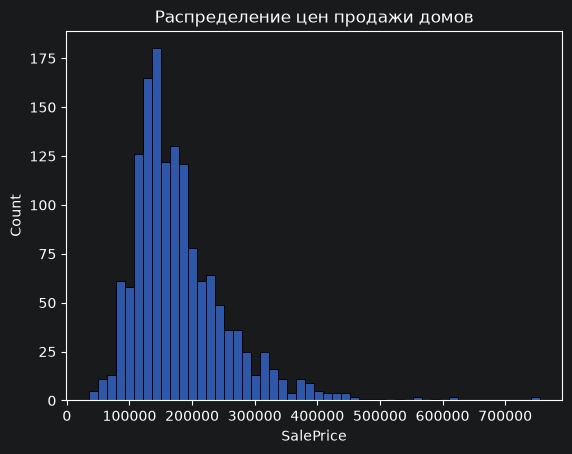

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [104]:
sns.histplot(data=train, x=train['SalePrice'], bins=50)
plt.title('Распределение цен продажи домов')
plt.show()
train['SalePrice'].describe()


У SalePrice - цена продажи дома - заметна правосторонняя асимметрия. Основная масса домов дешевле, а вправо тянется длинный хвост редких дорогих объектов. <br>
50% домов стоят от 129975 до 214000. Разброс цен между максимум и минимум большой. <br>
Цены сосредоточены в относительно низком диапазоне, дорогих домов значительно меньше. <br>

# Анализ влияние отдельных признаков

## Условно выделю наиболее значимые по смыслу признаки и рассмотрю их:
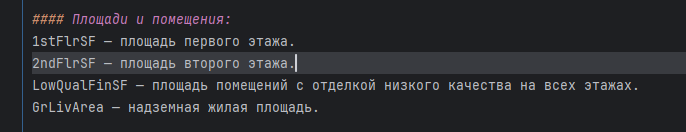

#### Расположение и окружение:
MSZoning - категория зонирования территории. <br>
Neighborhood - район города. <br>
Condition1 - особенности окружения: близость дороги, железной дороги, парка и т. п. <br>

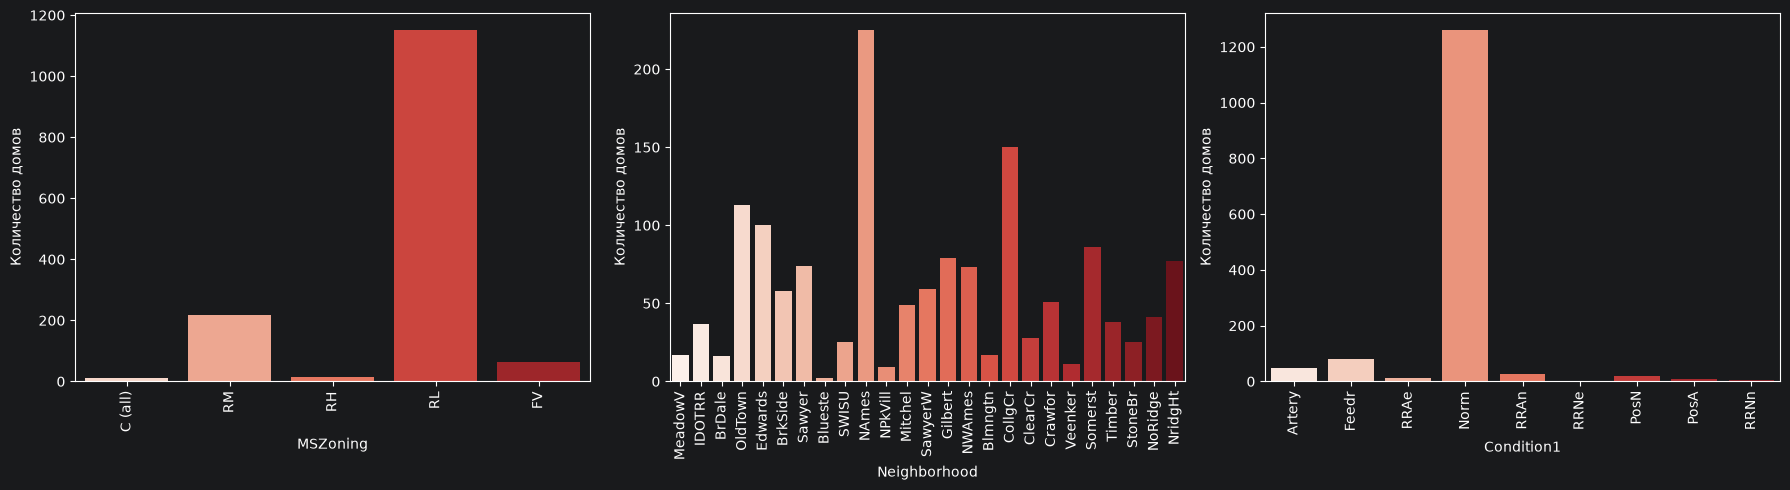

In [105]:
fig, axes = plt.subplots(1, 3, figsize=(18,5))
for col, feature in enumerate(['MSZoning', 'Neighborhood', 'Condition1']):
    order = train.groupby(feature)['SalePrice'].median().sort_values().index
    sns.countplot(data=train, x=feature, hue=feature,order=order, hue_order=order, palette='Reds', legend=False, ax=axes[col],)
    axes[col].tick_params(axis='x', labelrotation=90)
    axes[col].set_ylabel('Количество домов')

plt.tight_layout()
plt.show()


#### Общие выводы
На графиках высота столбцов показывает количество домов в каждой категории, а цвет - относительный уровень медианной цены продажи внутри каждого признака: чем темнее красный цвет, тем выше медианная цена. <br>
По MSZoning (категории зонирования) большинство домов относится к RL (жилая зона низкой плотности). Самая высокая медианная цена наблюдается в категории FV (205950`$`), хотя домов в ней заметно меньше - 65 против 1151 в RL. <br>
По Neighborhood (району города) медианные цены заметно различаются. В NridgHt медиана составляет 315000`$` по 77 продажам, а в самом представленном районе NAmes - 140000`$` по 225 продажам. <br>
По Condition1 (особенностям окружения) преобладает категория Norm (обычное окружение). У домов рядом с магистралью (Artery) и подъездной дорогой (Feedr) медианная цена ниже, чем в Norm.  <br>
Некоторые другие категории представлены единичными продажами. <br>

#### Земельный участок:
LotArea - площадь земельного участка. <br>
LandContour - рельеф участка. <br>

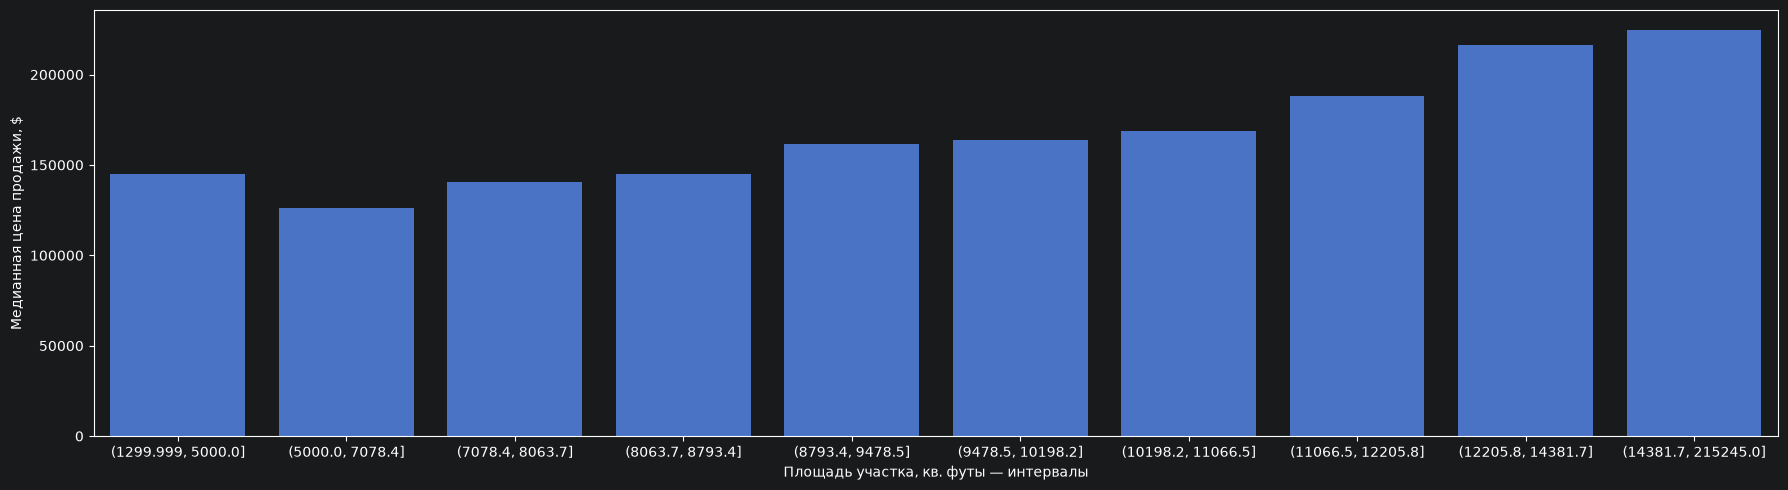

In [106]:
plt.figure(figsize=(18, 5))
sns.barplot(x=pd.qcut(train['LotArea'], q=10), y=train['SalePrice'], estimator='median', errorbar=None,)
plt.xlabel('Площадь участка, кв. футы — интервалы')
plt.ylabel('Медианная цена продажи, $')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

##### Наблюдается общая положительная связь: с увеличением площади участка медианная цена дома в целом растет

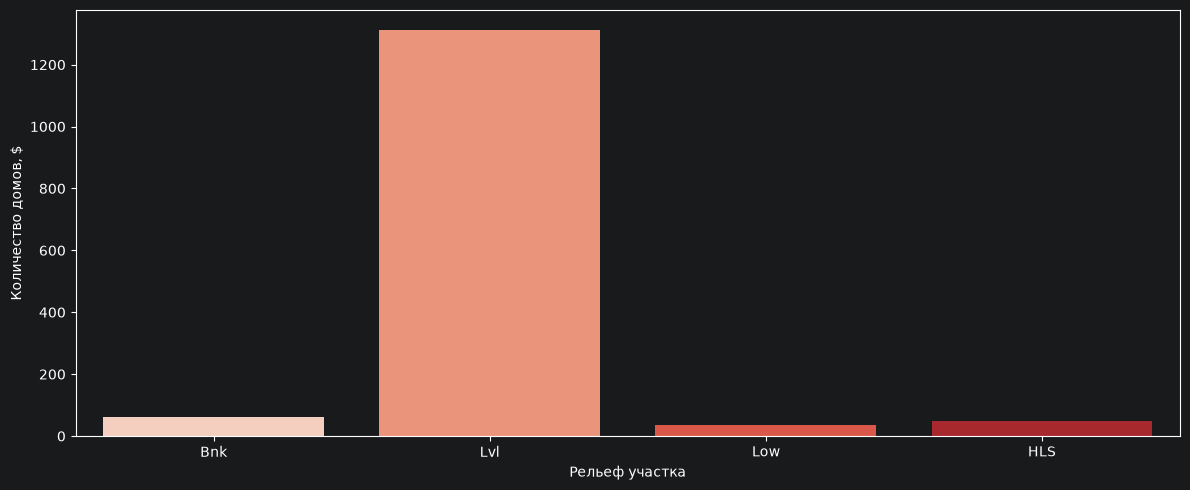

In [107]:
plt.figure(figsize=(12, 5))
order = train.groupby('LandContour')['SalePrice'].median().sort_values().index
sns.countplot(data=train, x='LandContour', hue='LandContour',order=order, hue_order=order, palette='Reds', legend=False)
plt.xlabel('Рельеф участка')
plt.ylabel('Количество домов, $')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

##### Большинство домов расположено на почти ровных участках (Lvl). Наибольшая медианная цена продажи наблюдается у домов на склонах (HLS), а наименьшая - у домов на участках с резким подъёмом от улицы к зданию (Bnk).

#### Тип и общее состояние дома:

MSSubClass - категория жилья с учётом этажности, возраста и типа здания. <br>
BldgType - тип жилого здания: отдельный дом, дуплекс, таунхаус и т. п. <br>
HouseStyle - этажность и конфигурация этажей дома. <br>
OverallQual - общая оценка качества материалов и отделки. <br>
OverallCond - общая оценка состояния дома. <br>

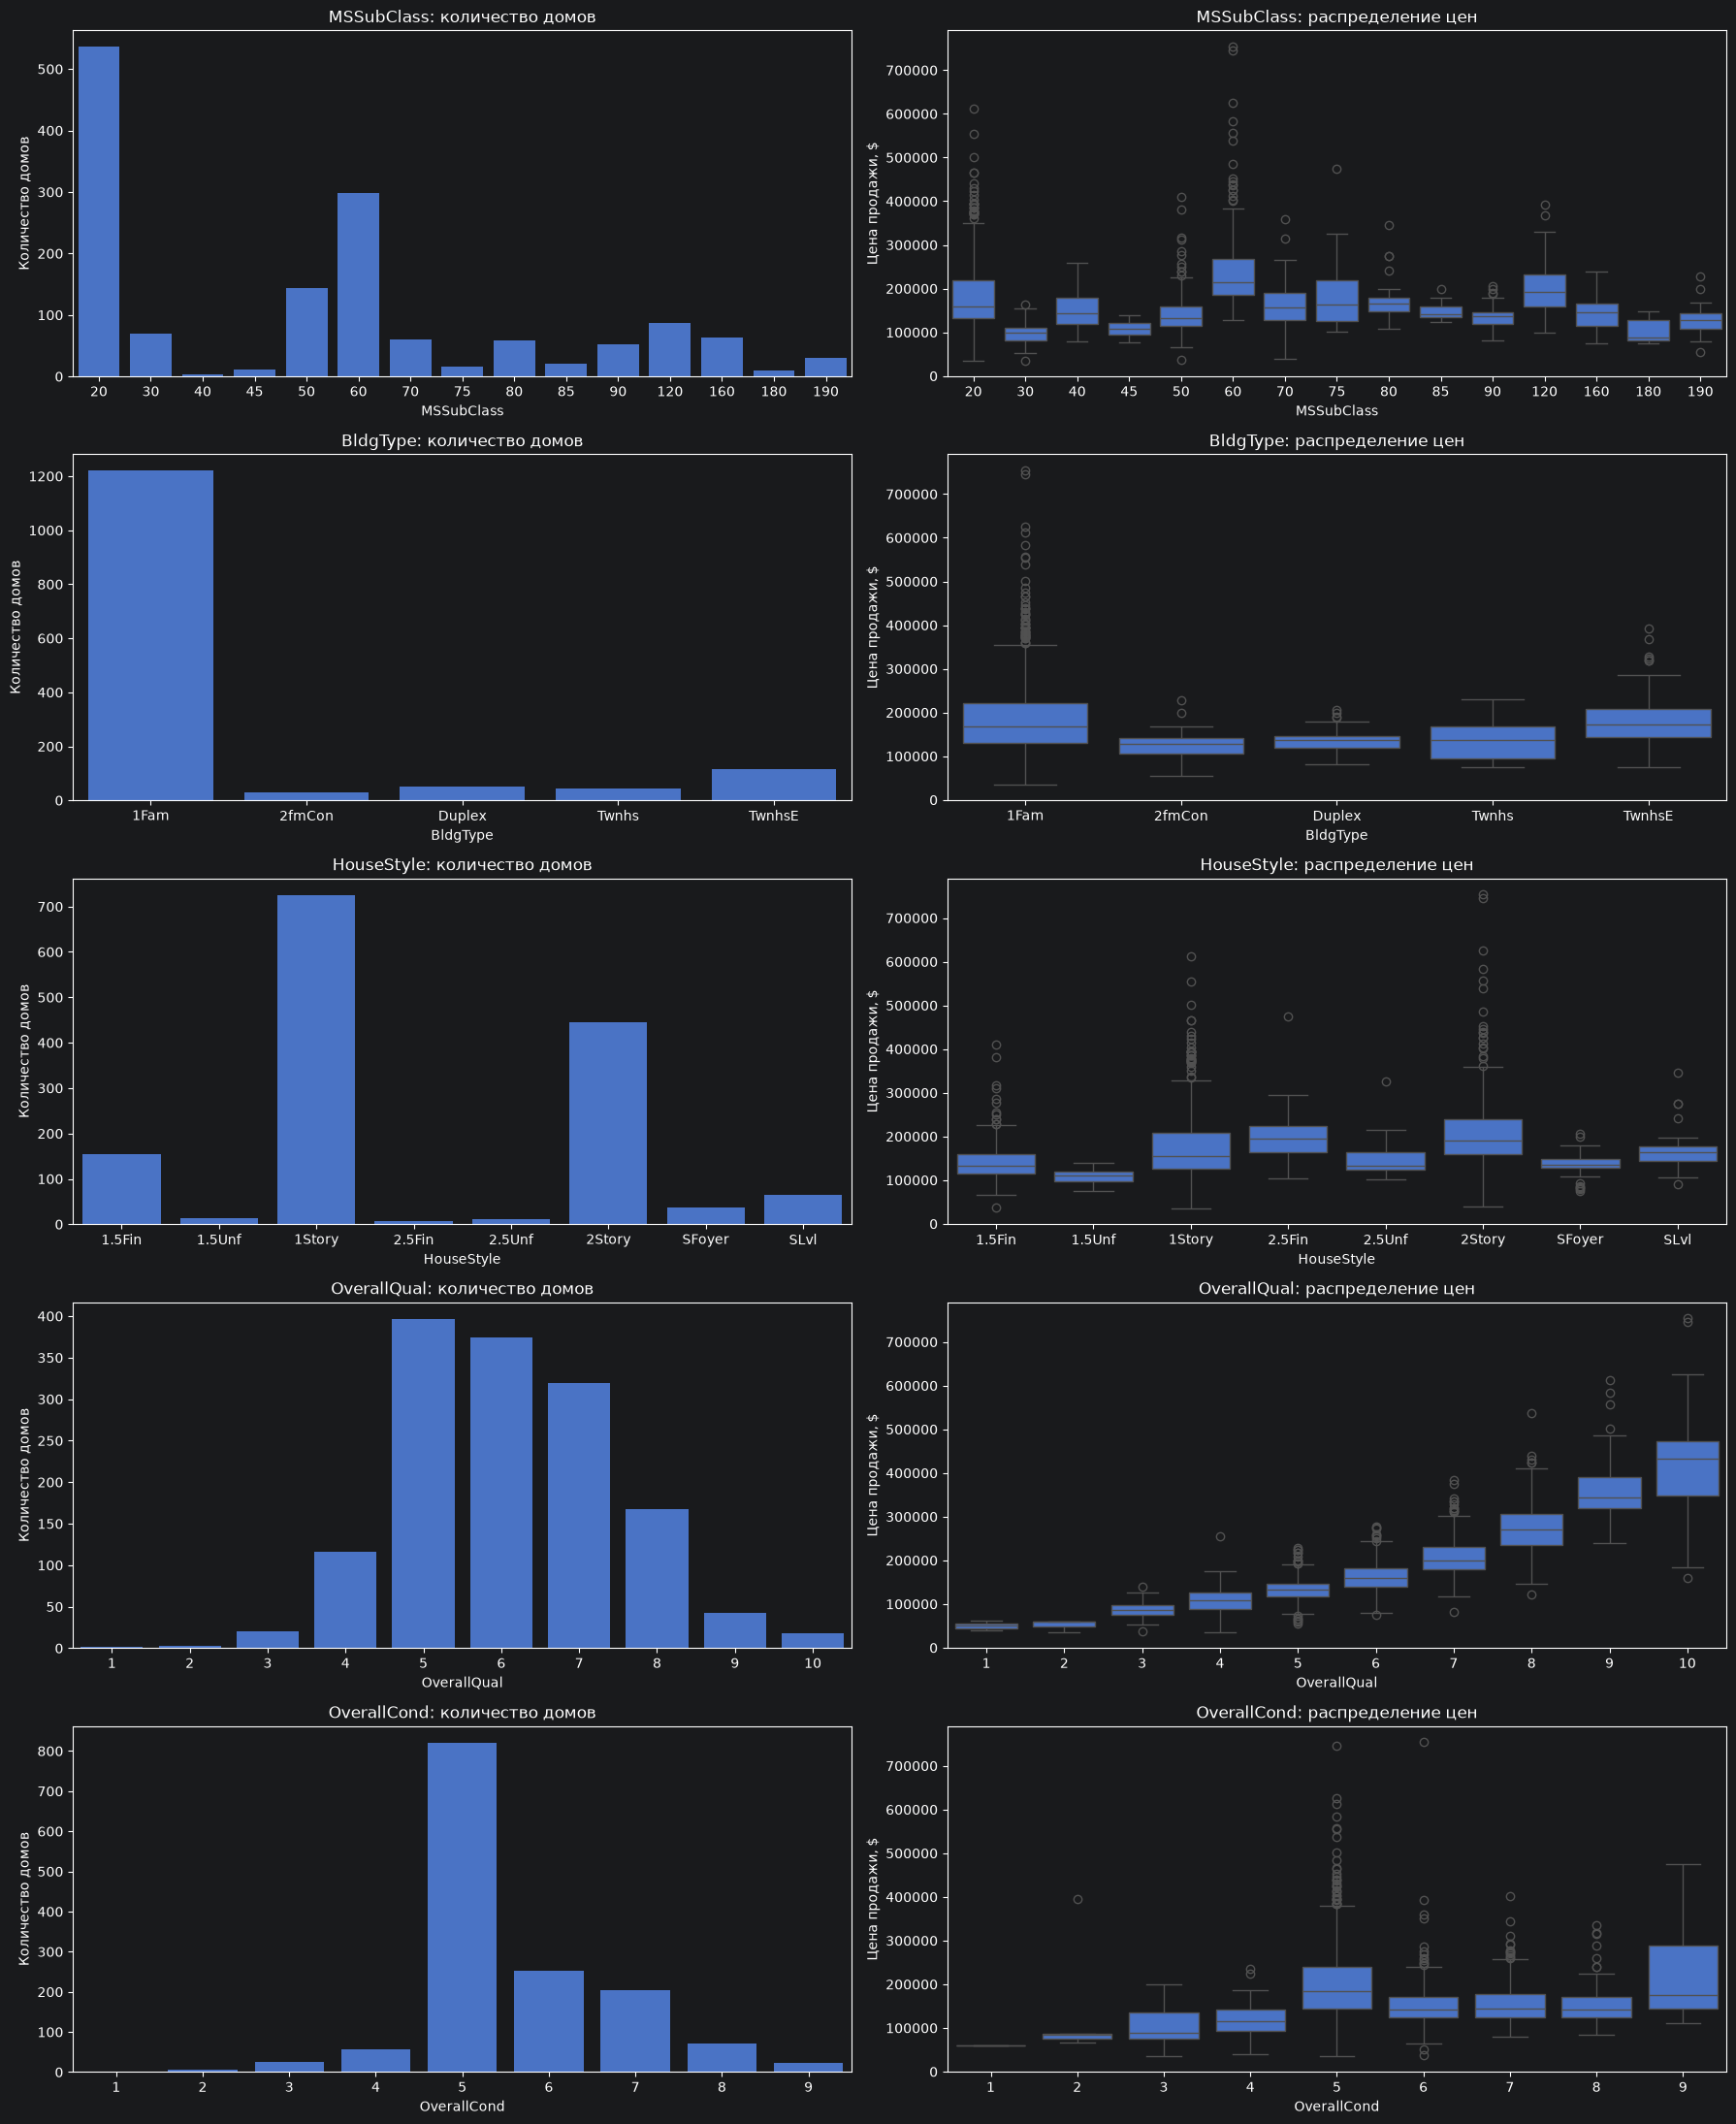

In [108]:
fig, axes = plt.subplots(5, 2, figsize=(18, 22))
for row, feature in enumerate(['MSSubClass', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond']):
    order = sorted(train[feature].dropna().unique())
    sns.countplot(data=train, x=feature,order=order, ax=axes[row, 0],)
    axes[row, 0].set_title(f'{feature}: количество домов')
    axes[row, 0].set_ylabel('Количество домов')

    sns.boxplot(data=train, x=feature, y='SalePrice', order=order, ax=axes[row, 1])
    axes[row, 1].set_title(f'{feature}: распределение цен')
    axes[row, 1].set_ylabel('Цена продажи, $')

    for ax in axes[row]:
        ax.tick_params(axis='x', labelrotation=0)

plt.tight_layout()
plt.show()

### Основные выводы:
Признак OverallQual имеет сильную положительную связь с ценой (boxplot). <br>
Однако OverallCond не так сильно связана с ценой. <br>
Чаще всего встречаются дома среднего качества и среднего состояния. <br>
Также можно заметить признаки с категорией жилья, типом жилого здания и этажной конфигурацией различаются по распределению цен и могут быть информативны.

#### Крыша, наружная отделка и фундамент, общее состояние подвала, инженерные системы и функциональность:
ExterQual - оценка качества наружных материалов. <br>
ExterCond - оценка состояния наружных материалов. <br>
Foundation - тип фундамента. <br>
BsmtCond - общее состояние подвала. <br>
HeatingQC - качество и состояние отопления. <br>
Functional - оценка функциональности дома и наличия эксплуатационных недостатков. <br>

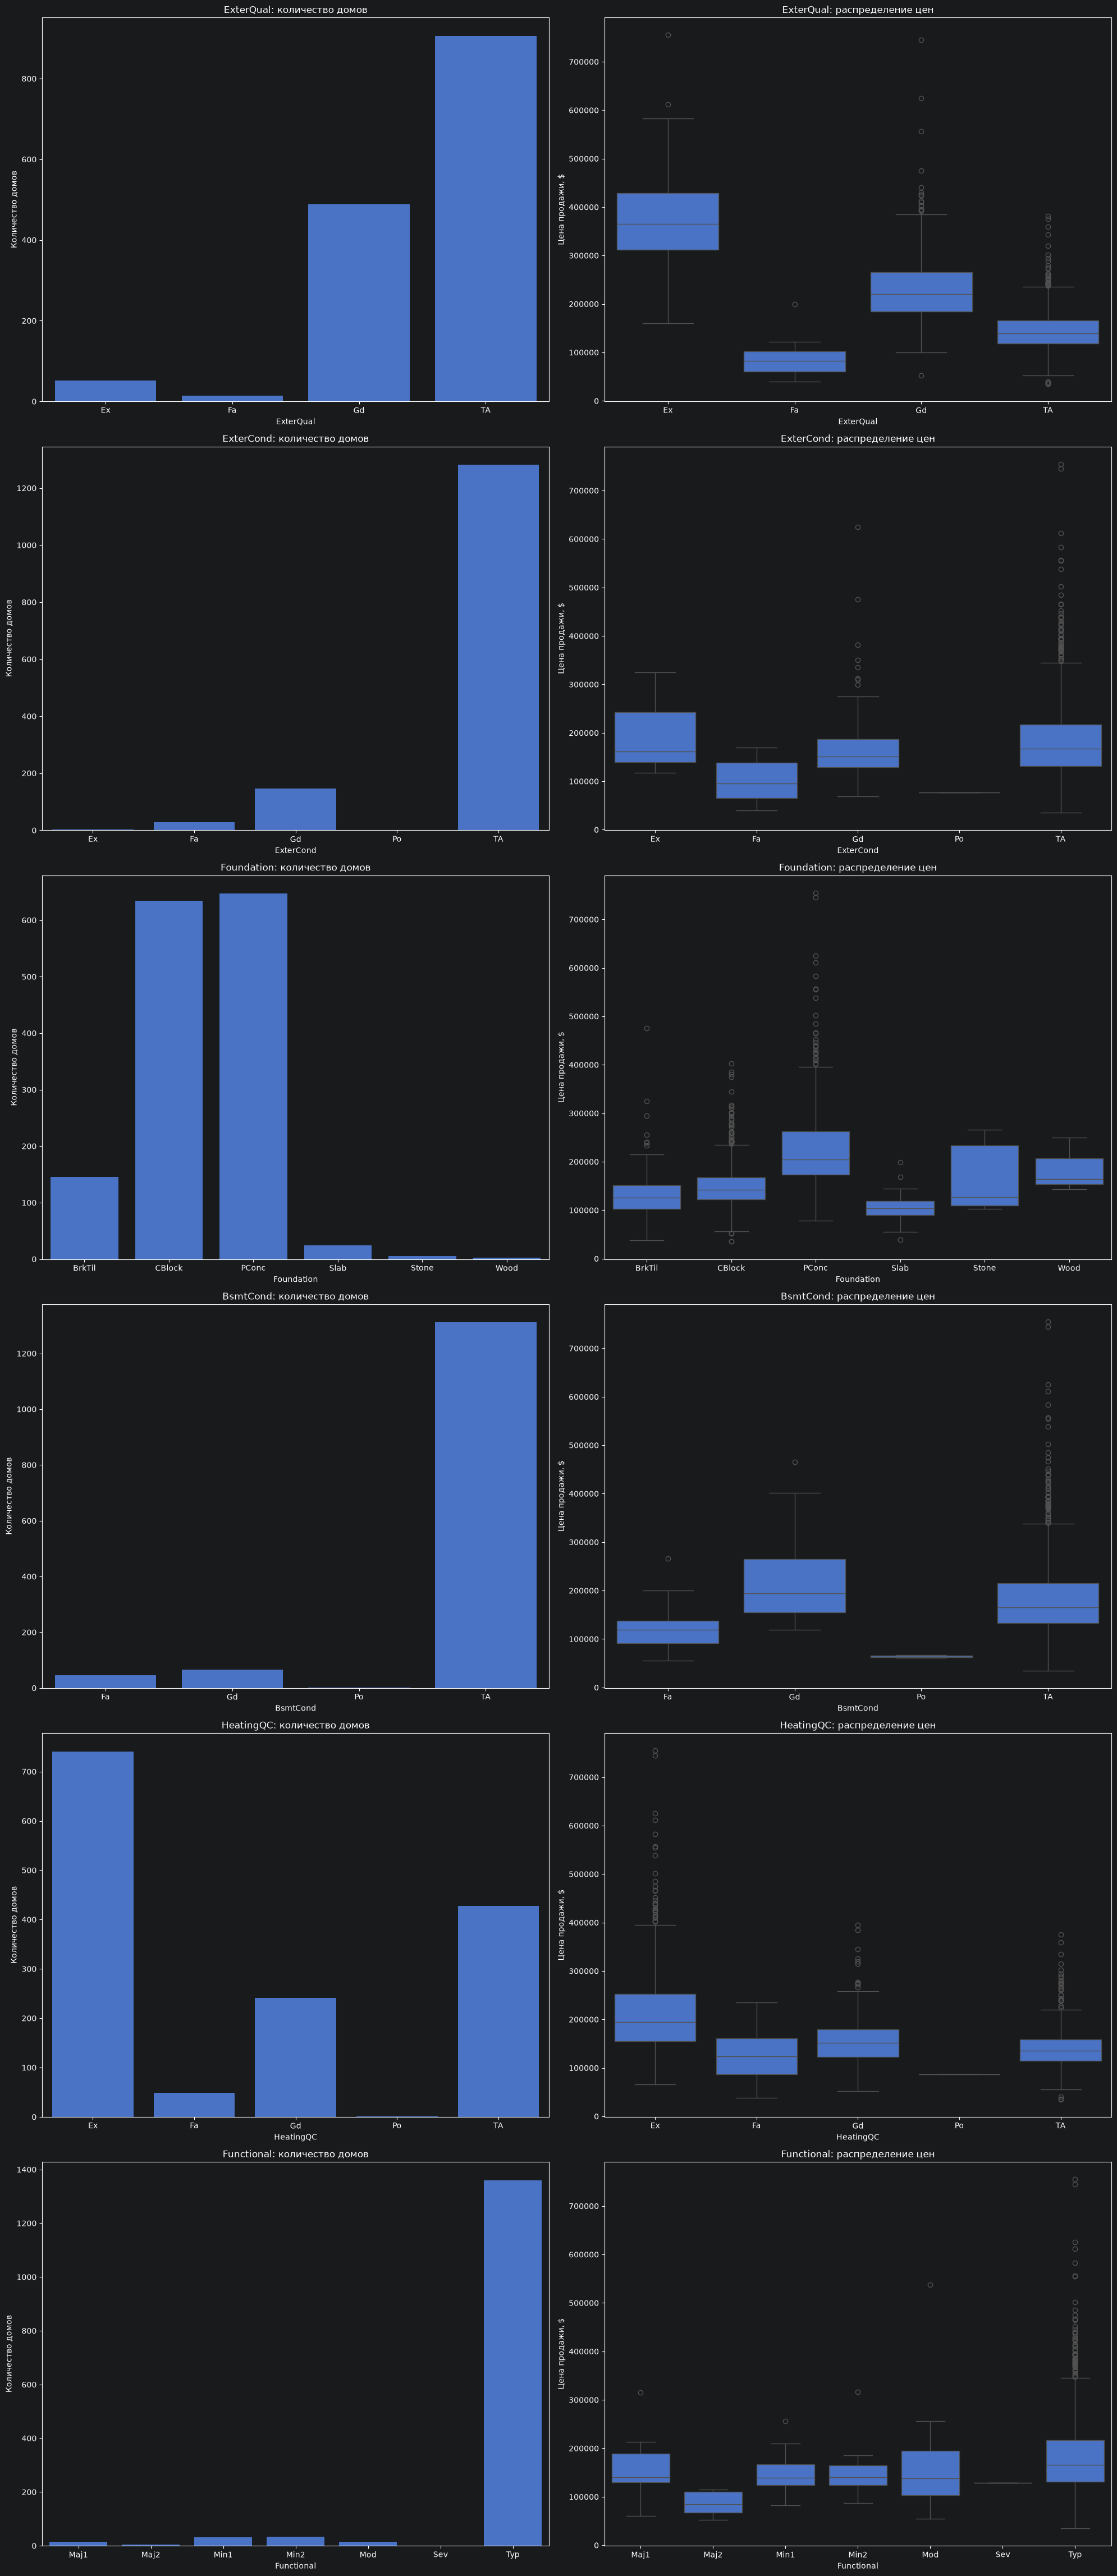

In [109]:
fig, axes = plt.subplots(6, 2, figsize=(20,46))
for row, feature in enumerate(['ExterQual', 'ExterCond', 'Foundation', 'BsmtCond', 'HeatingQC', 'Functional']):
    order = sorted(train[feature].dropna().unique())
    sns.countplot(data=train, x=feature,order=order, ax=axes[row, 0],)
    axes[row, 0].set_title(f'{feature}: количество домов')
    axes[row, 0].set_ylabel('Количество домов')

    sns.boxplot(data=train, x=feature, y='SalePrice', order=order, ax=axes[row, 1])
    axes[row, 1].set_title(f'{feature}: распределение цен')
    axes[row, 1].set_ylabel('Цена продажи, $')

    for ax in axes[row]:
        ax.tick_params(axis='x', labelrotation=0)

plt.tight_layout()
plt.show()

### Основные выводы:
Качество наружных материалов дома имеет сильную положительную связь с ценой. <br>
Оценка состояния наружных материалов такой выраженной связи не имеет. В основном встречается оценка TA(Typical/Average). В некоторых категориях слишком мало домов. <br>
Дома с каменным и деревянным фундаментами встречаются редко. В основном это PConc(монолитный бетон) или CBlock(бетонные блоки). У домов с PConc самая высокая медианная цена <br>

Состояние подвала имеет связь с ценой. Чаще всего встречается обычное/среднее состояние, Дома с хорошим состоянием подвала имеют более высокую медианную цену, чем дома со средним состоянием. <br>
Можно предположить, что медианные цены домов с подвалами хуже среднего ниже медианных цен остальных домов, но это нельзя сказать точно из-за того, что домов с подвалом состоянием хуже среднего(Fa) или плохим(Po) очень мало. <br>

Качество отопления связано с ценой. Медианные цены домов с отоплением с оценками Ex(отлично), Gd(хорошо) выше остальных, а с Fa(хуже среднего) и Po(плохо) - ниже. <br>
Домов с плохой оценкой за отопление очень мало, поэтому вывод может быть не совсем точным. <br>

По признаку Functional виден сильный дисбаланс категорий, подавляющее число домов имеет обычную полноценную функциональность. Распределения цен заметно перекрываются. Проблемных домов мало, поэтому сравнение ограничено.

#### Подвал:
BsmtUnfSF - площадь неотделанной части подвала. <br>
TotalBsmtSF - общая площадь подвала. <br>

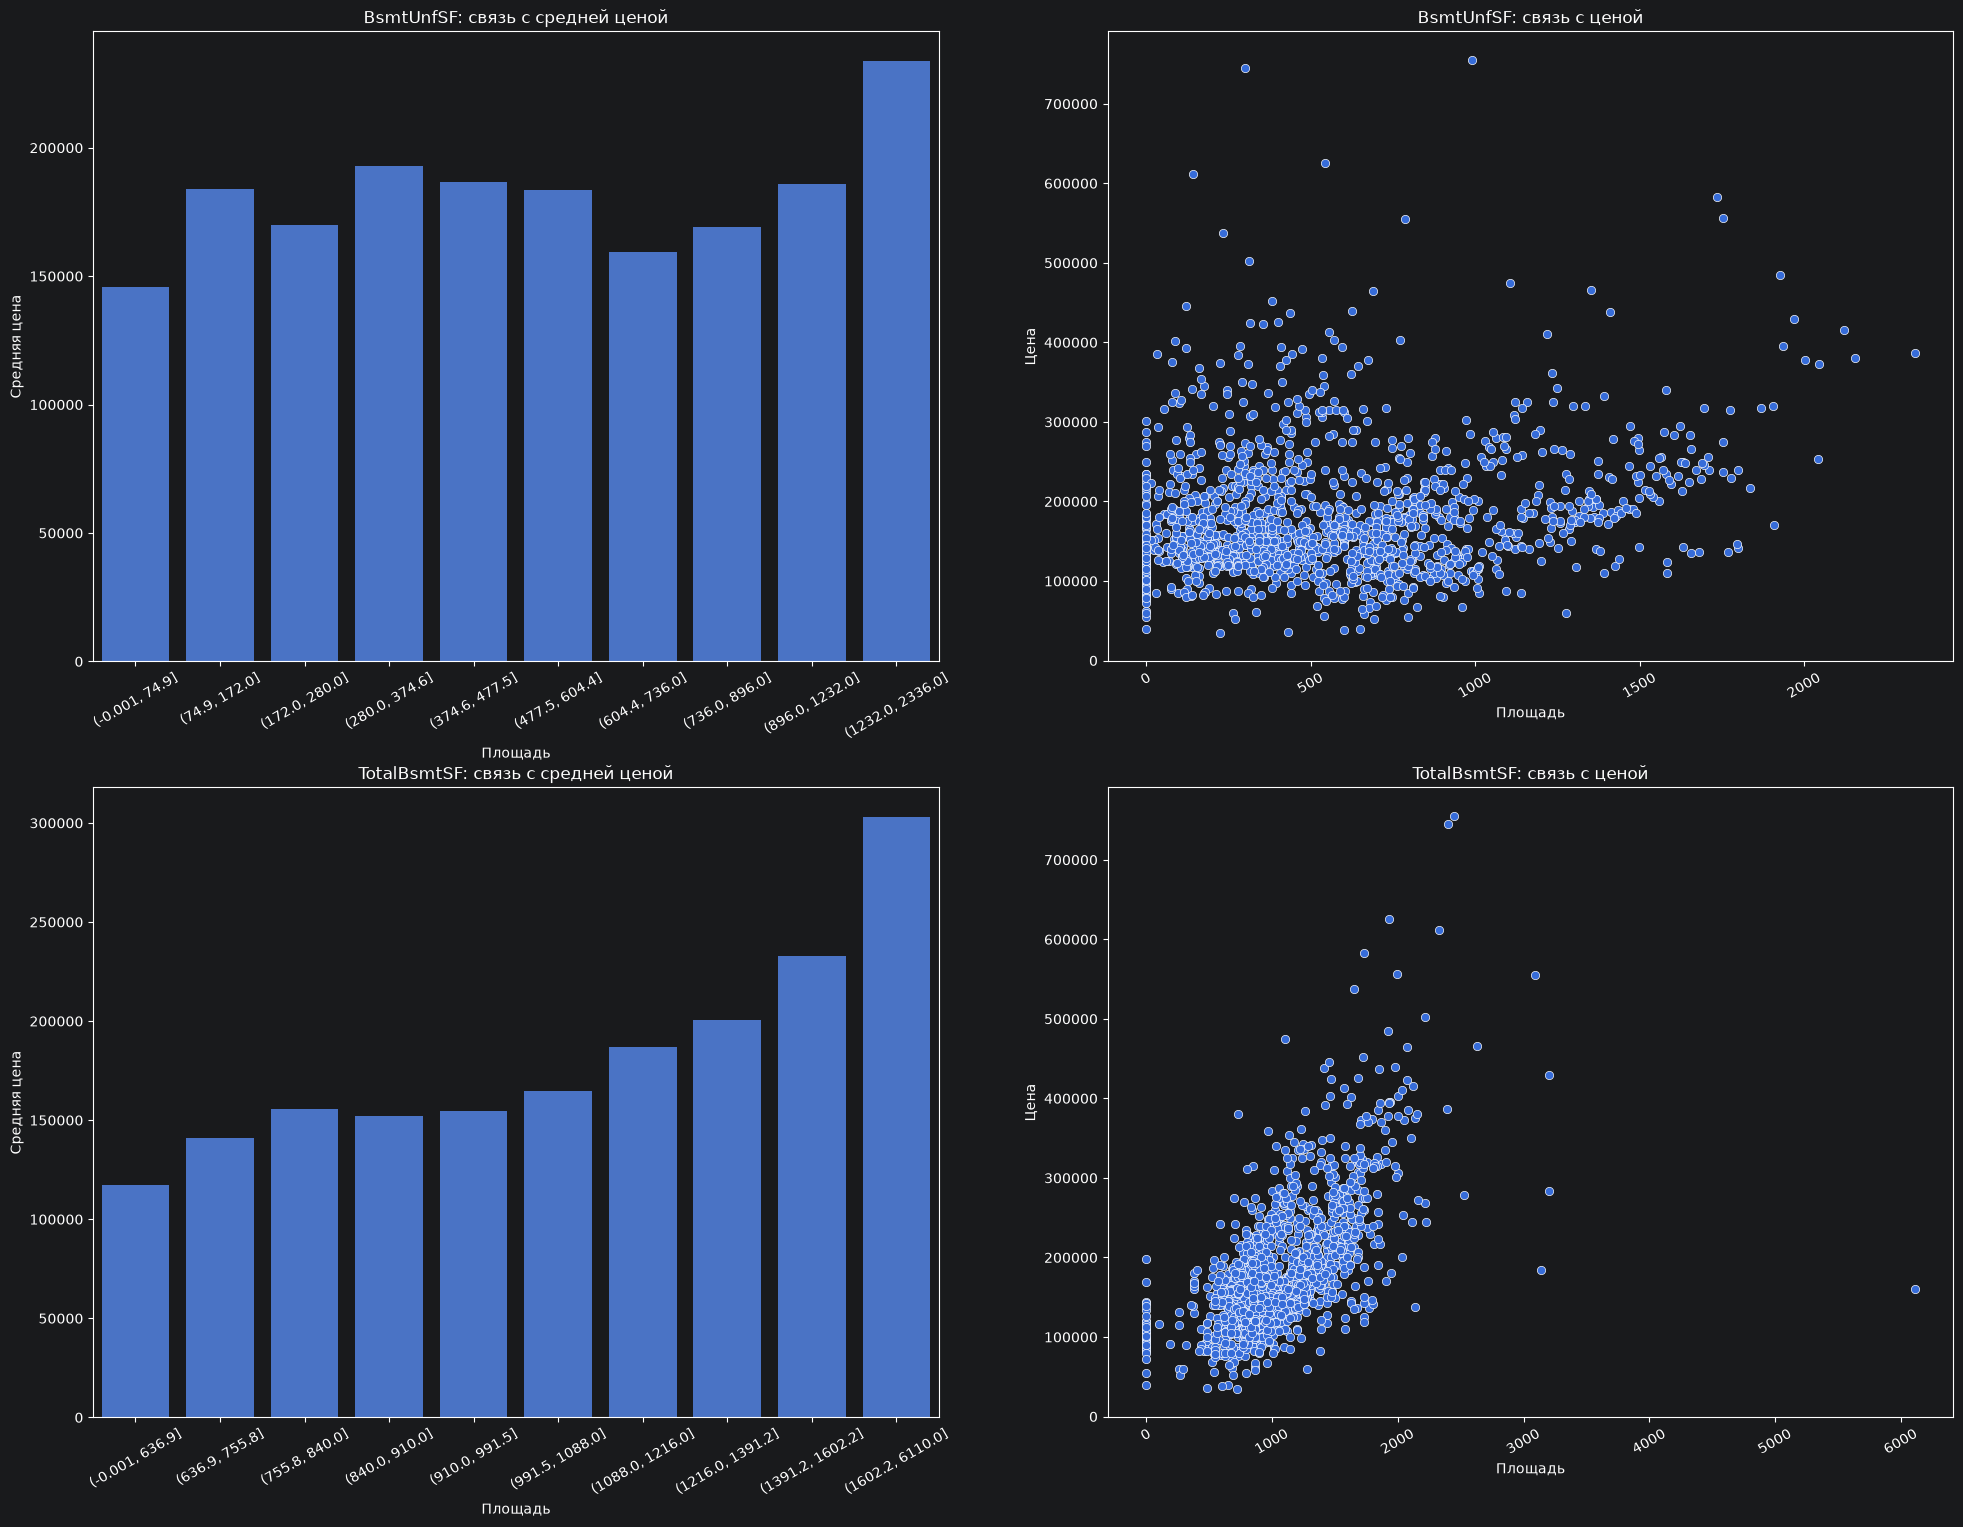

In [110]:
fig, axes = plt.subplots(2, 2, figsize=(24, 18))
for row, feature in enumerate(['BsmtUnfSF', 'TotalBsmtSF']):
    sns.barplot(x=pd.qcut(train[feature], q=10), y=train['SalePrice'], estimator='mean', errorbar=None, ax=axes[row, 0])
    axes[row, 0].set_title(f'{feature}: связь с средней ценой')
    axes[row, 0].set_ylabel('Средняя цена')
    axes[row, 0].set_xlabel('Площадь')

    sns.scatterplot(x=train[feature], y=train['SalePrice'], ax=axes[row,1])
    axes[row, 1].set_title(f'{feature}: связь c ценой')
    axes[row, 1].set_ylabel('Цена')
    axes[row, 1].set_xlabel('Площадь')

    for ax in axes[row]:
        ax.tick_params(axis='x', labelrotation=30)

### Общие выводы:
Заметна положительная связь общей площади подвала с ценой. По бинам цена в целом растет, а на scatter plot облако точек вытянуто вверх и вправо. <br>
У признака BsmtUnfSF(общая площадь неотделанной части подвала) такой последовательной тенденции нет. Цена колеблется между бинами, а на scatter plot большой разброс. <br>
Также на scatter plot выделяется дом с подвалом около 6100 кв. футов и ценой около 160 тыс. Его стоит посмотреть отдельно. <br>

#### Площади и помещения:
1stFlrSF - площадь первого этажа. <br>
2ndFlrSF - площадь второго этажа. <br>
GrLivArea - надземная жилая площадь. <br>
LowQualFinSF - площадь помещений с отделкой низкого качества на всех этажах. <br>
BedroomAbvGr - количество спален на надземных этажах. <br>
KitchenQual - оценка качества кухни. <br>
SecondFloorPresent - наличие второго этажа <br>

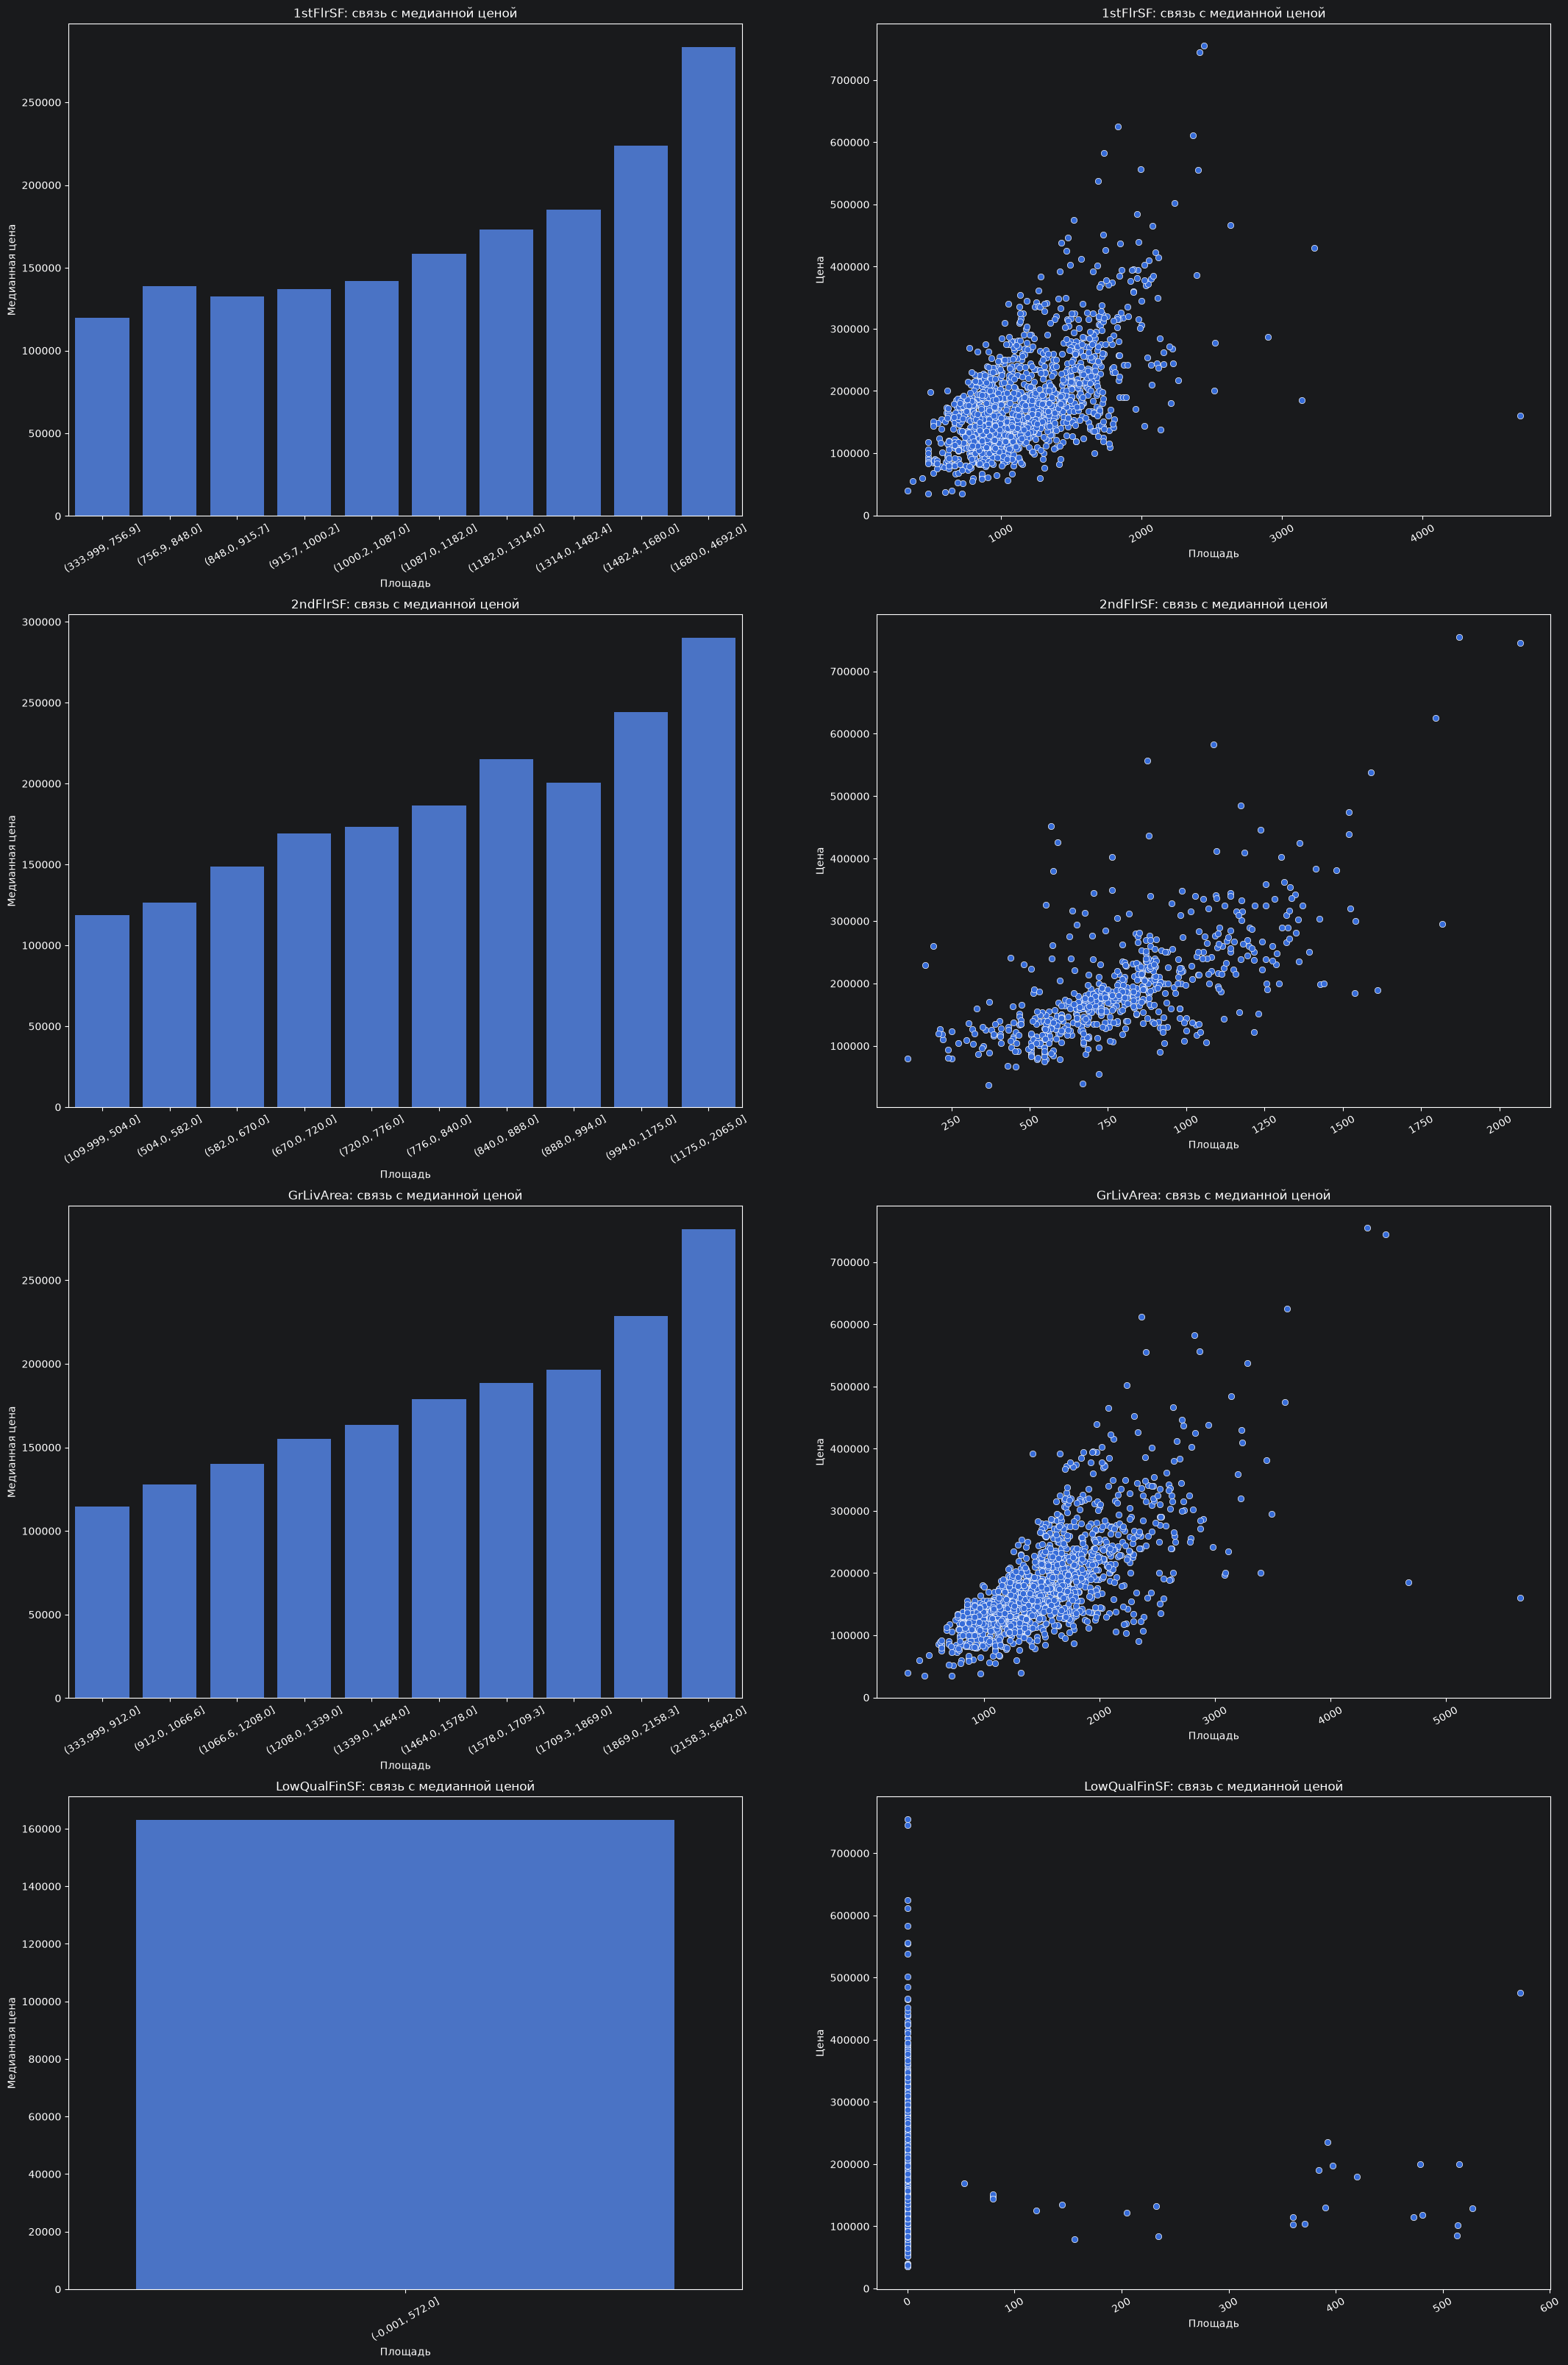

In [111]:
houses_with_second_floor = train[train['2ndFlrSF'] != 0]
fig, axes = plt.subplots(4, 2, figsize=(26, 40))

for row, feature in enumerate(['1stFlrSF', '2ndFlrSF', 'GrLivArea', 'LowQualFinSF']):
    plot_data = houses_with_second_floor if feature == '2ndFlrSF' else train
    sns.barplot(x=pd.qcut(plot_data[feature], q=10, duplicates='drop'), y=plot_data['SalePrice'], estimator='median', errorbar=None, ax=axes[row, 0])
    axes[row, 0].set_title(f'{feature}: связь с медианной ценой')
    axes[row, 0].set_ylabel('Медианная цена')
    axes[row, 0].set_xlabel('Площадь')

    sns.scatterplot(data=plot_data, x=feature, y='SalePrice', ax=axes[row,1])
    axes[row, 1].set_title(f'{feature}: связь c медианной ценой')
    axes[row, 1].set_ylabel('Цена')
    axes[row, 1].set_xlabel('Площадь')
    for ax in axes[row]:
        ax.tick_params(axis='x', labelrotation=30)

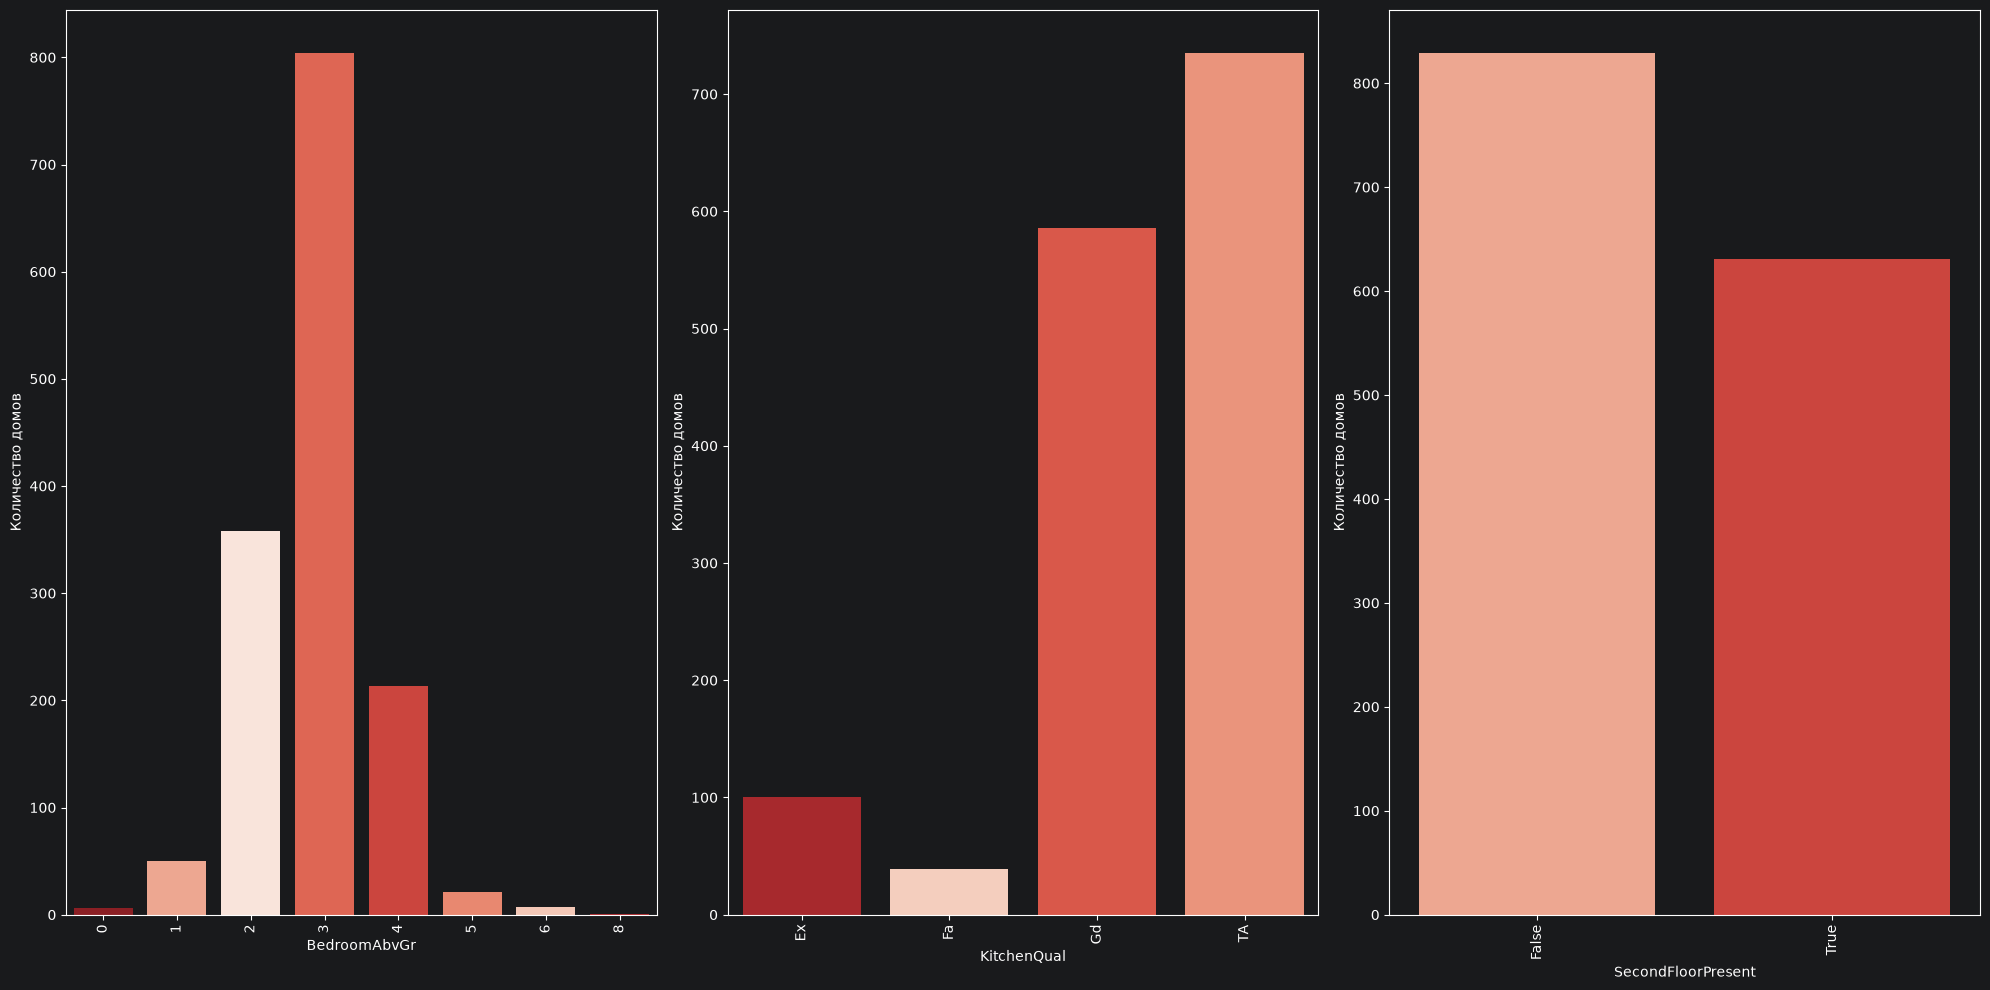

In [112]:
second_floor_present = (train['2ndFlrSF'] != 0)
updated_train = train.copy()
updated_train['SecondFloorPresent'] = second_floor_present

fig, axes = plt.subplots(1, 3, figsize=(20,10))
for col, feature in enumerate(['BedroomAbvGr', 'KitchenQual', 'SecondFloorPresent']):
    order = sorted(updated_train[feature].dropna().unique())
    price_order = updated_train.groupby(feature)['SalePrice'].median().sort_values().index
    sns.countplot(data=updated_train, x=feature, hue=feature,order=order, hue_order=price_order, palette=sns.color_palette('Reds', n_colors=len(order)), legend=False, ax=axes[col],)
    axes[col].tick_params(axis='x', labelrotation=90)
    axes[col].set_ylabel('Количество домов')

plt.tight_layout()
plt.show()

### Общие выводы
Признаки 1stFlrSF(площадь первого этажа), 2ndFlrSF(площадь второго этажа), GrLivArea(надземная жилая площадь) имеют сильную положительную связь с ценой. <br>
Признак LowQualFinSF оказался почти константным, в нем большинство значений - 0. <br>
Нулевые значения признака 2ndFlrSF не рассматривались, поэтому дополнительно проведен и анализ нового признака SecondFloorPresent, описывающего наличие второго этажа(True) или его отсутствие(False). <br>
График показал, что медианная цена домов, где есть второй этаж выше, по сравнению с теми домами, где его нет.

По графику признака, описывающего количество спален (BedroomAbvGr) видно, что наиболее часто встречается значение 3. При значении 2 медианная цена наименьшая, при 0 и 8 - наибольшая (данных для оценки этих категорий слишком мало). <br>
Можно сделать вывод, что большее число спален не всегда означает большую цену дома. <br>
График признака KitchenQual(качество кухни) показал, что дома с кухнями, значение качества которых относится к категории Ex(отличное), имеют наивысшую медианную цену. <br>
По графику видно, что чем выше оценка качества кухни, тем выше медианная цена дома. <br>

#### Доп объекты на участке (численные признаки):

PoolArea - площадь бассейна. <br>
GarageArea - площадь гаража. <br>
MiscVal - стоимость дополнительного объекта в долларах. <br>

Количество домов с бассейном(train): 7
Количество домов с заполненным PoolQC(train) :  7
Домов без бассейна :  1453
Дома с ненулевой стоимостью доп. объекта :  52


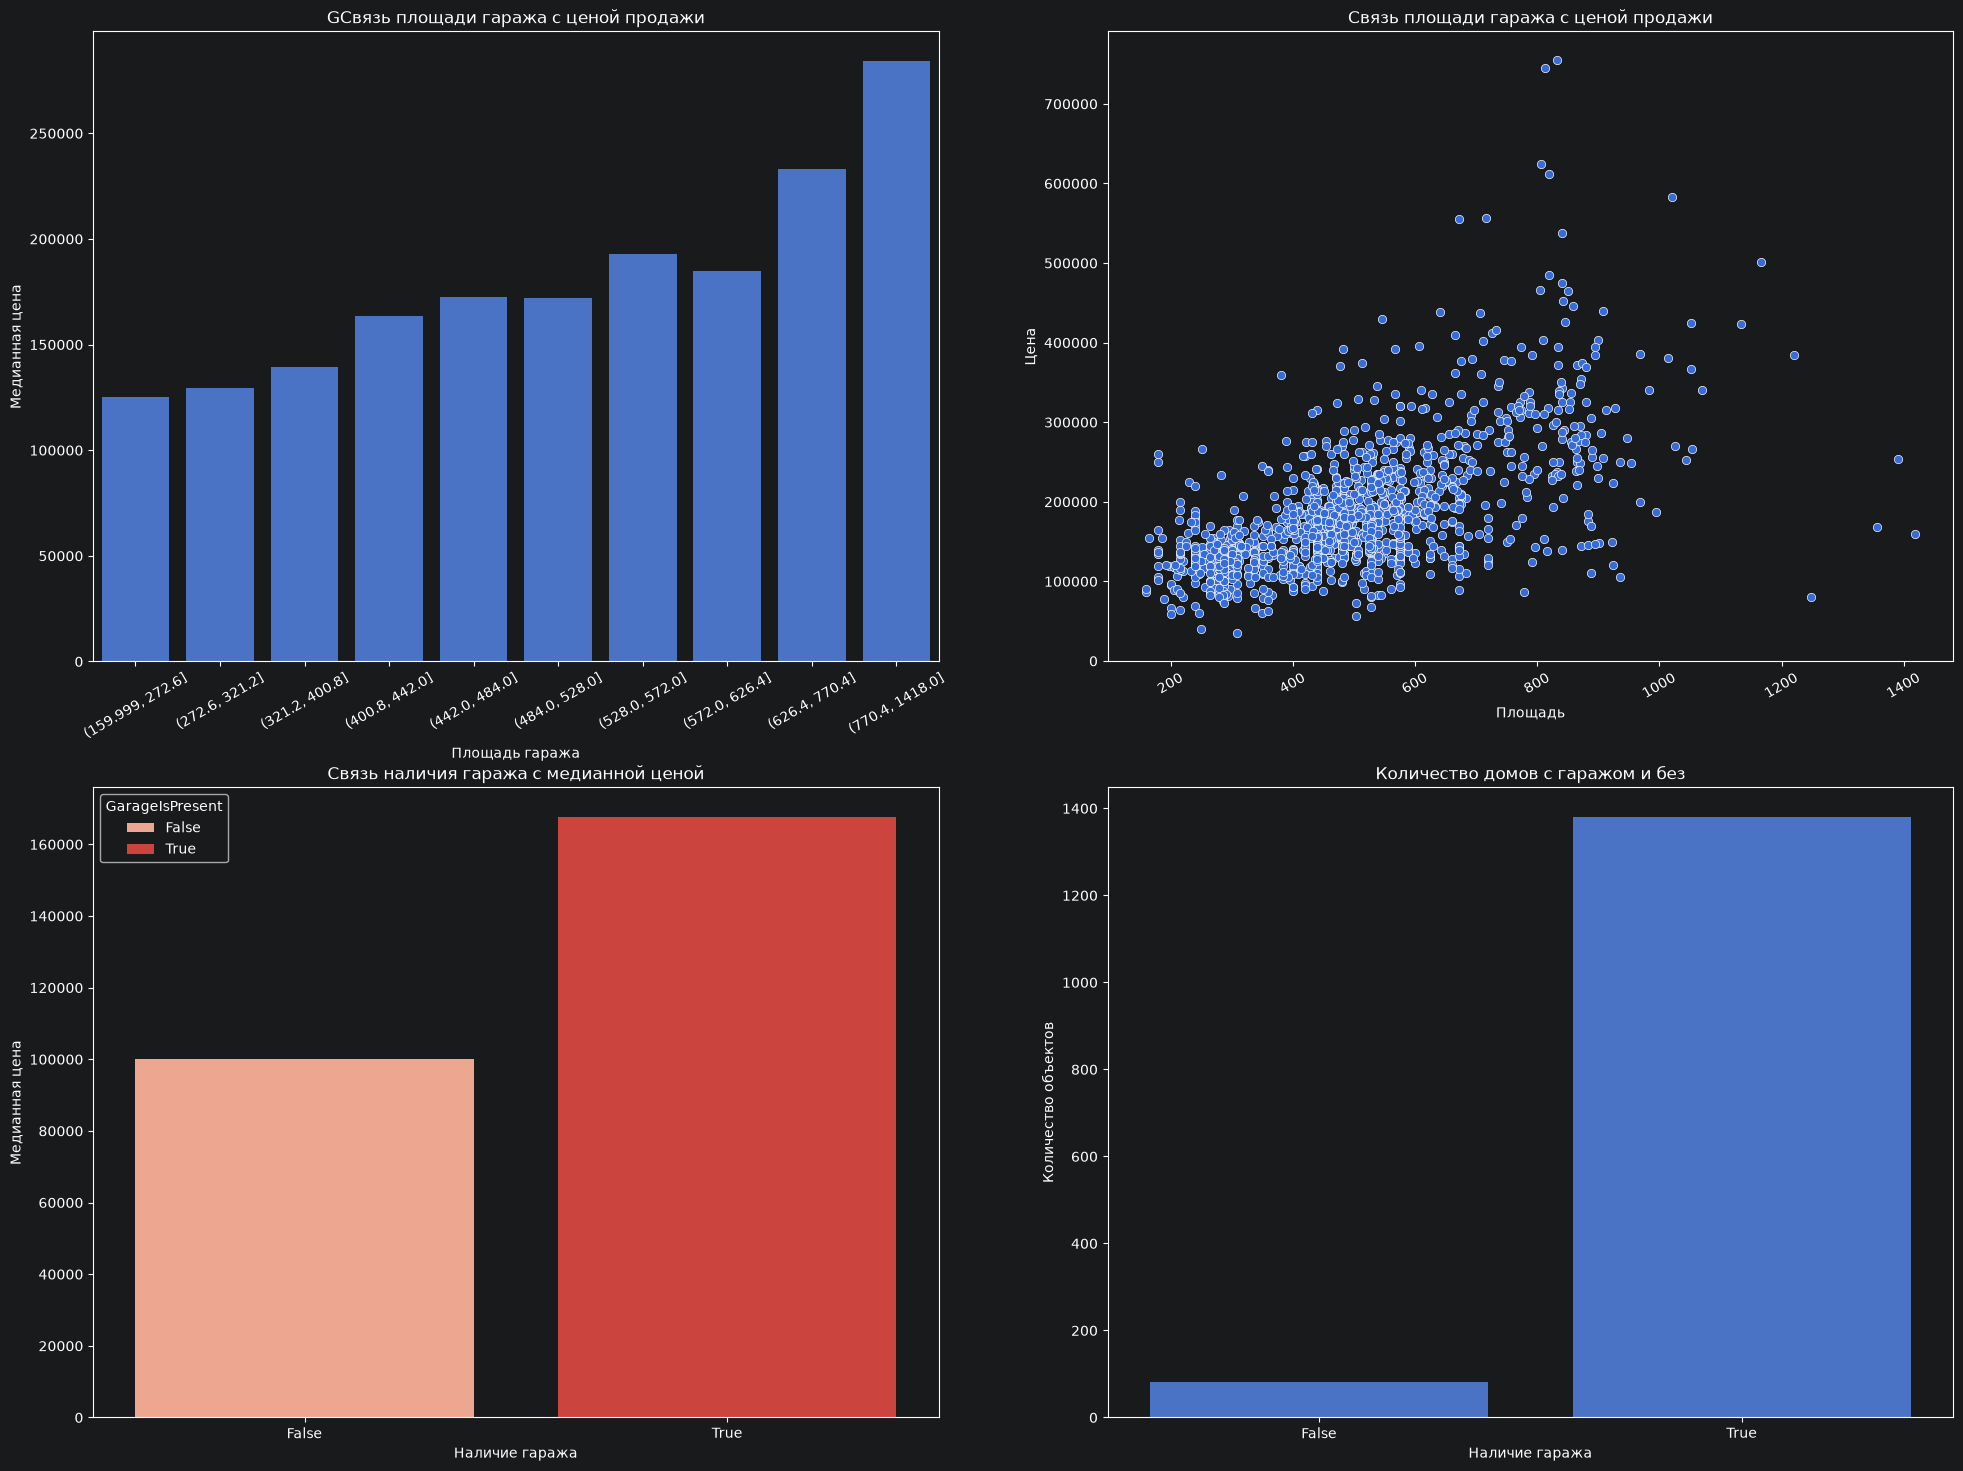

In [113]:
houses_with_garage = (train['GarageArea'] != 0)
houses_with_pool = (train['PoolArea'] != 0)
houses_updated = train.copy()
houses_updated['GarageIsPresent'] = houses_with_garage
houses_updated['PoolIsPresent'] = houses_with_pool
plot_data = houses_updated.loc[houses_updated['GarageIsPresent']]

print('Количество домов с бассейном(train):', len(houses_updated[houses_updated['PoolIsPresent'] == True]))
print('Количество домов с заполненным PoolQC(train) : ', len(houses_updated[houses_updated['PoolQC'].notna()]))
print('Домов без бассейна : ', len(houses_updated[houses_updated['PoolIsPresent'] == False]))
print('Дома с ненулевой стоимостью доп. объекта : ', len(houses_updated[houses_updated['MiscVal'] != 0]))

fig, axes = plt.subplots(2, 2, figsize=(24,18))
ax = axes[0, 0]
sns.barplot(x=pd.qcut(plot_data['GarageArea'], q=10, duplicates='drop'), y=plot_data['SalePrice'], estimator='median', errorbar=None, ax=ax)
ax.set_title(f'GСвязь площади гаража с ценой продажи')
ax.set_ylabel('Медианная цена')
ax.set_xlabel('Площадь гаража')
ax.tick_params(axis='x', labelrotation=30)
ax = axes[0, 1]
sns.scatterplot(data=plot_data, x='GarageArea', y='SalePrice', ax=ax)
ax.set_title(f'Связь площади гаража с ценой продажи')
ax.set_ylabel('Цена')
ax.set_xlabel('Площадь')
ax.tick_params(axis='x', labelrotation=30)

ax=axes[1,0]
price_order = houses_updated.groupby('GarageIsPresent')['SalePrice'].median().sort_values().index
sns.barplot(data=houses_updated, x='GarageIsPresent', y='SalePrice', hue='GarageIsPresent', hue_order=price_order, estimator='median',  palette=sns.color_palette('Reds', n_colors=len(price_order)), errorbar=None, ax=ax)
ax.set_title(f'Cвязь наличия гаража c медианной ценой')
ax.set_ylabel('Медианная цена')
ax.set_xlabel('Наличие гаража')
ax.tick_params(axis='x', labelrotation=0)

ax=axes[1,1]
sns.countplot(data=houses_updated, x='GarageIsPresent', order=[False, True], ax=ax)
ax.set_title(f'Количество домов с гаражом и без')
ax.set_ylabel('Количество объектов')
ax.set_xlabel('Наличие гаража')
ax.tick_params(axis='x', labelrotation=0)



#### Выводы по численным признакам раздела:

Бассейн есть только у 7 из 1460 домов. Этого мало для уверенного сравнения цен по PoolArea (площади бассейна) и PoolQC (качеству бассейна). <br>
У 52 из 1460 домов указана ненулевая стоимость доп. объекта(MiscVal). Из-за редкости ненулевых значений связь этого признака с ценой продажи отдельно не рассматривалась. <br>
У домов с гаражом медианная цена выше, чем у домов без него. У большинства домов есть гараж.  <br>
Cреди домов с гаражом медианная цена продажи в целом выше в группах с большей GarageArea (площадью гаража). <br>

#### Доп объекты на участке (категориальные признаки):

PoolQC - оценка качества бассейна. <br>
Fence - тип и качество забора. <br>
GarageFinish - степень внутренней отделки гаража. <br>
GarageQual - оценка качества гаража. <br>
GarageCond - оценка состояния гаража. <br>


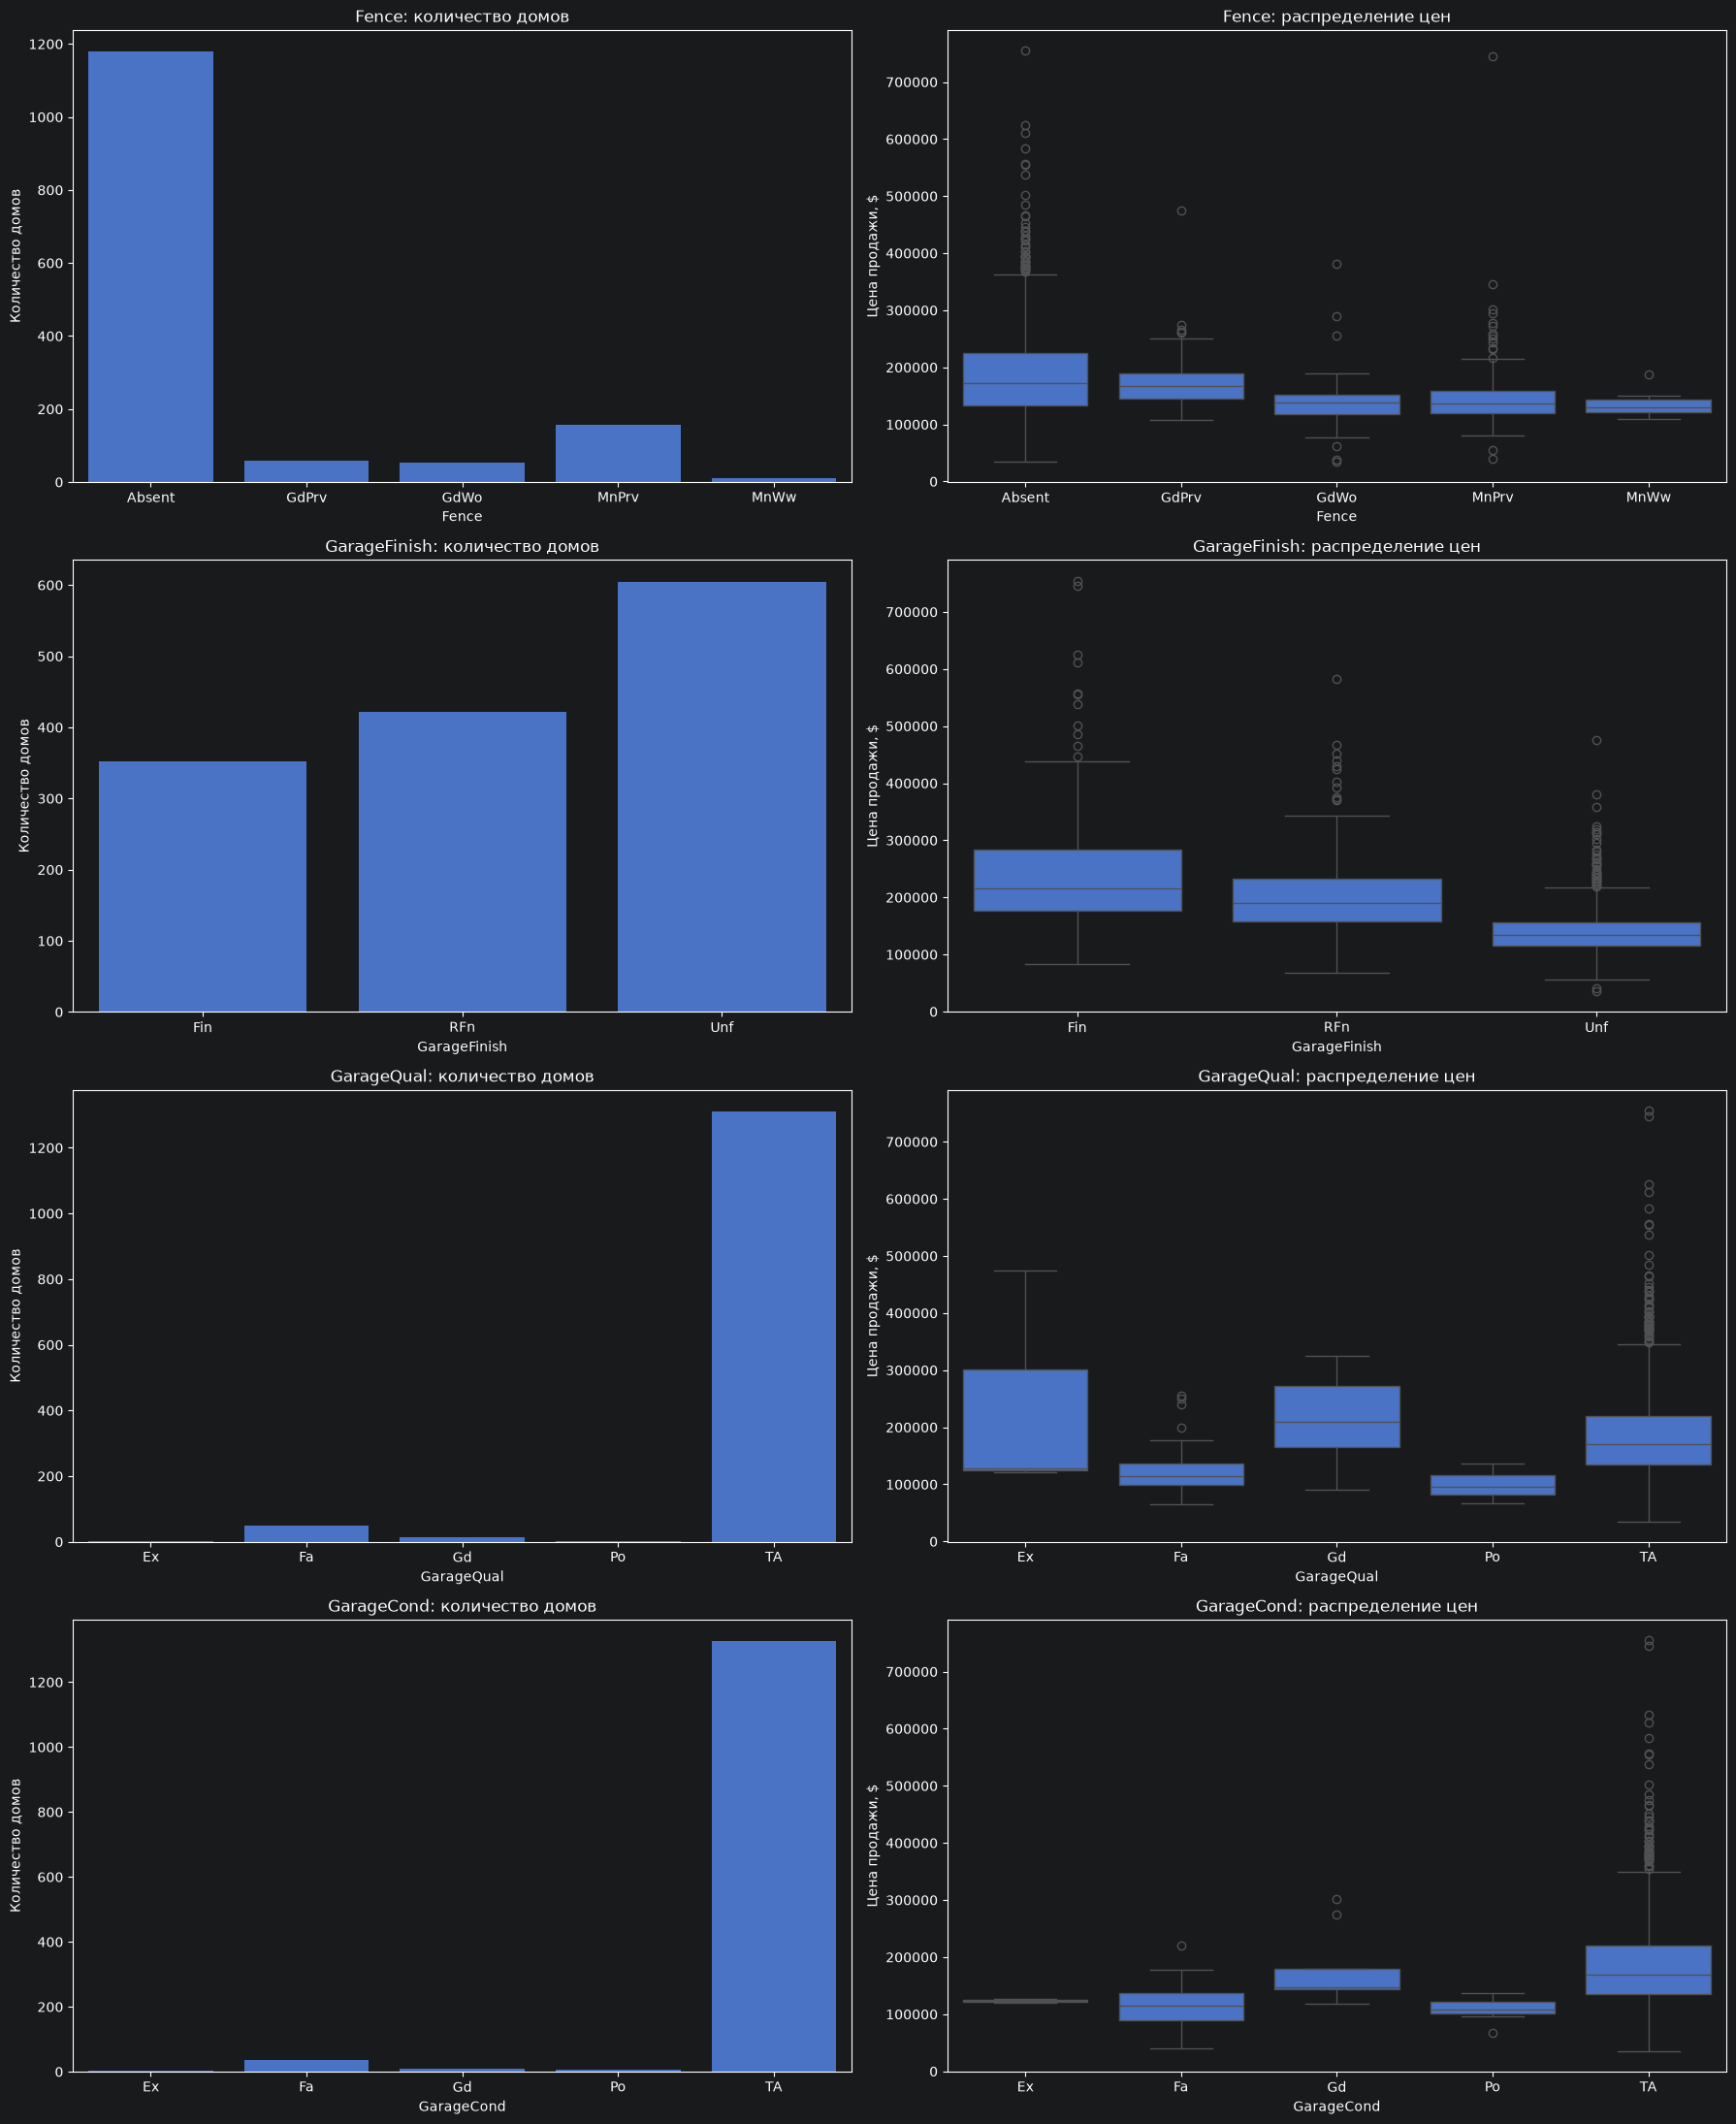

In [114]:
fig, axes = plt.subplots(4, 2, figsize=(18, 22))
plot_data = train.copy()
plot_data.loc[plot_data['Fence'].isna(), 'Fence'] = 'Absent'
for row, feature in enumerate(['Fence', 'GarageFinish', 'GarageQual', 'GarageCond']):
    order = sorted(plot_data[feature].dropna().unique())
    sns.countplot(data=plot_data, x=feature,order=order, ax=axes[row, 0],)
    axes[row, 0].set_title(f'{feature}: количество домов')
    axes[row, 0].set_ylabel('Количество домов')

    sns.boxplot(data=plot_data, x=feature, y='SalePrice', order=order, ax=axes[row, 1])
    axes[row, 1].set_title(f'{feature}: распределение цен')
    axes[row, 1].set_ylabel('Цена продажи, $')

    for ax in axes[row]:
        ax.tick_params(axis='x', labelrotation=0)

plt.tight_layout()
plt.show()

#### Выводы по категориальным признакам:

У большинства гаражей качество (GarageQual) и состояние (GarageCond) оценены как TA (обычное). Медианная цена продажи не показывает последовательного роста с повышением этих оценок. <br>
По Fence (типу и качеству забора) среди домов с забором самая высокая медианная цена наблюдается в категории GdPrv (хороший забор, закрывающий участок от обзора). Некоторые категории малочисленны, трудно оценить связь данного признака с ценой. <br>
По GarageFinish (степени внутренней отделки гаража) виден рост медианной цены: от гаражей без отделки (Unf) к гаражам с черновой (RFn) и завершённой отделкой (Fin). <br>

#### Продажа:
MoSold - месяц продажи. <br>
YrSold - год продажи. <br>
SaleType - тип сделки продажи. <br>
SaleCondition - обстоятельства и условия продажи. <br>

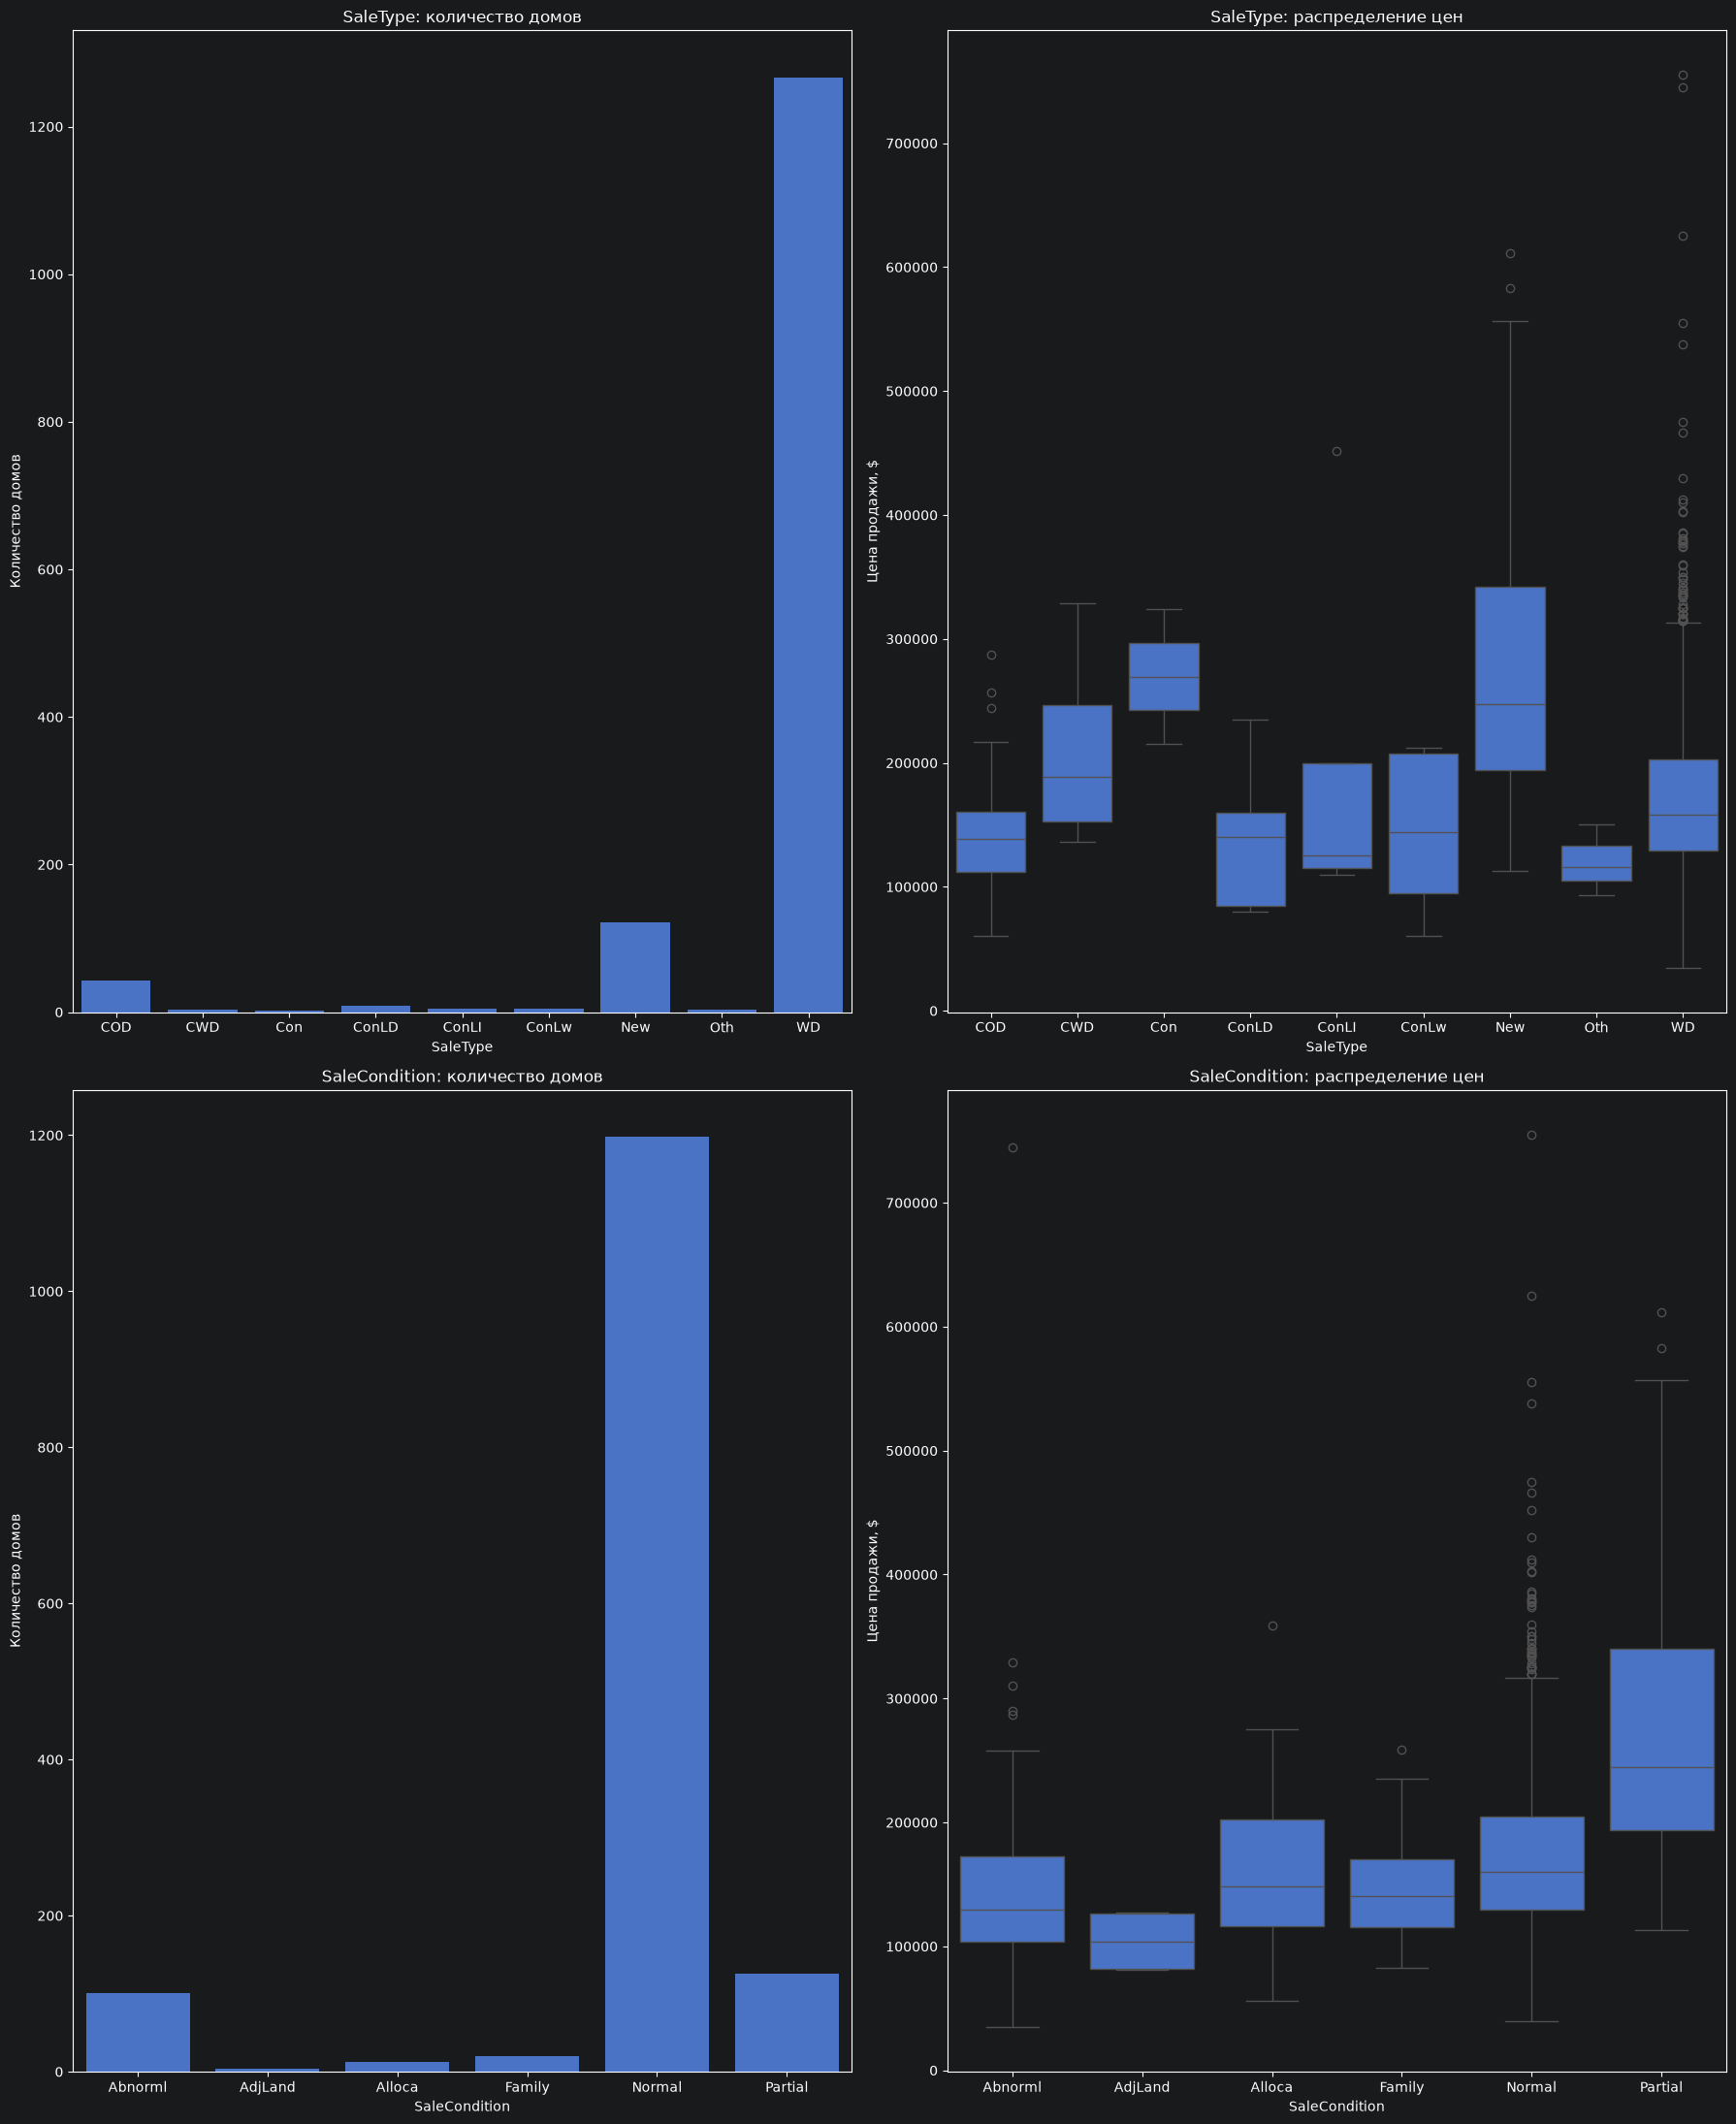

In [115]:
fig, axes = plt.subplots(2, 2, figsize=(18, 22))
for row, feature in enumerate(['SaleType', 'SaleCondition']):
    order = sorted(train[feature].dropna().unique())
    sns.countplot(data=train, x=feature,order=order, ax=axes[row, 0],)
    axes[row, 0].set_title(f'{feature}: количество домов')
    axes[row, 0].set_ylabel('Количество домов')

    sns.boxplot(data=train, x=feature, y='SalePrice', order=order, ax=axes[row, 1])
    axes[row, 1].set_title(f'{feature}: распределение цен')
    axes[row, 1].set_ylabel('Цена продажи, $')

    for ax in axes[row]:
        ax.tick_params(axis='x', labelrotation=0)

plt.tight_layout()
plt.show()

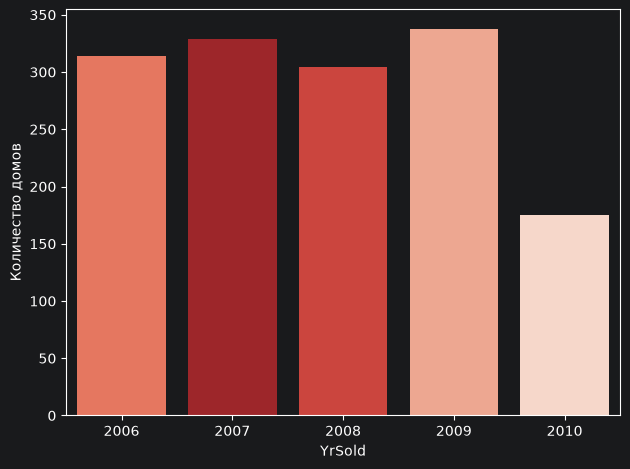

In [116]:
#YrSold
order = sorted(train['YrSold'].dropna().unique())
price_order = train.groupby('YrSold')['SalePrice'].median().sort_values().index
sns.countplot(data=train, x='YrSold', hue='YrSold',order=order, hue_order=price_order, palette=sns.color_palette('Reds', n_colors=len(order)), legend=False)
plt.ylabel('Количество домов')

plt.tight_layout()
plt.show()

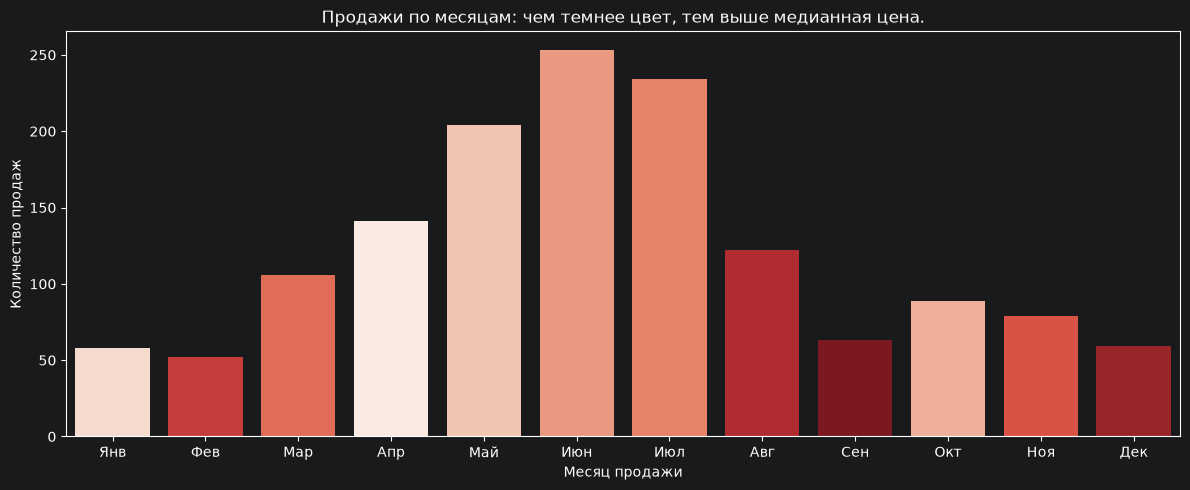

In [117]:
price_order = train.groupby('MoSold')['SalePrice'].median().sort_values().index

fig, ax = plt.subplots(figsize=(12, 5))
sns.countplot(data=train, x='MoSold', order=range(1, 13), hue='MoSold', hue_order=price_order,palette=sns.color_palette('Reds', n_colors=len(price_order)),legend=False,ax=ax)
ax.set_xticks(range(12), ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн','Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек'])
ax.set_title('Продажи по месяцам: чем темнее цвет, тем выше медианная цена.')
ax.set_xlabel('Месяц продажи')
ax.set_ylabel('Количество продаж')
plt.tight_layout()
plt.show()

#### Общие выводы:
Большинство сделок относятся к WD (обычный тип сделки) и Normal (обычные обстоятельства продажи). <br>
У домов в категориях New (продажа новостройки) и Partial (дом не был достроен на момент последней оценки) медианная цена заметно выше, чем в обычных сделках. Многие другие категории малочисленны <br>
По YrSold (году продажи) самая высокая медианная цена наблюдалась в 2007 году. С 2008 по 2010 год медиана снизилась с 164000$ до 155000$. Данные за 2010 год охватывают только январь–июль. <br>
По MoSold (месяцу продажи) самая высокая медианная цена была в сентябре (185900$), а больше всего продаж было в июне и июле. <br>
Стоит отдельно рассмотреть дома по комбинации месяца и года продаж, чтобы получить более репрезентативные выводы.

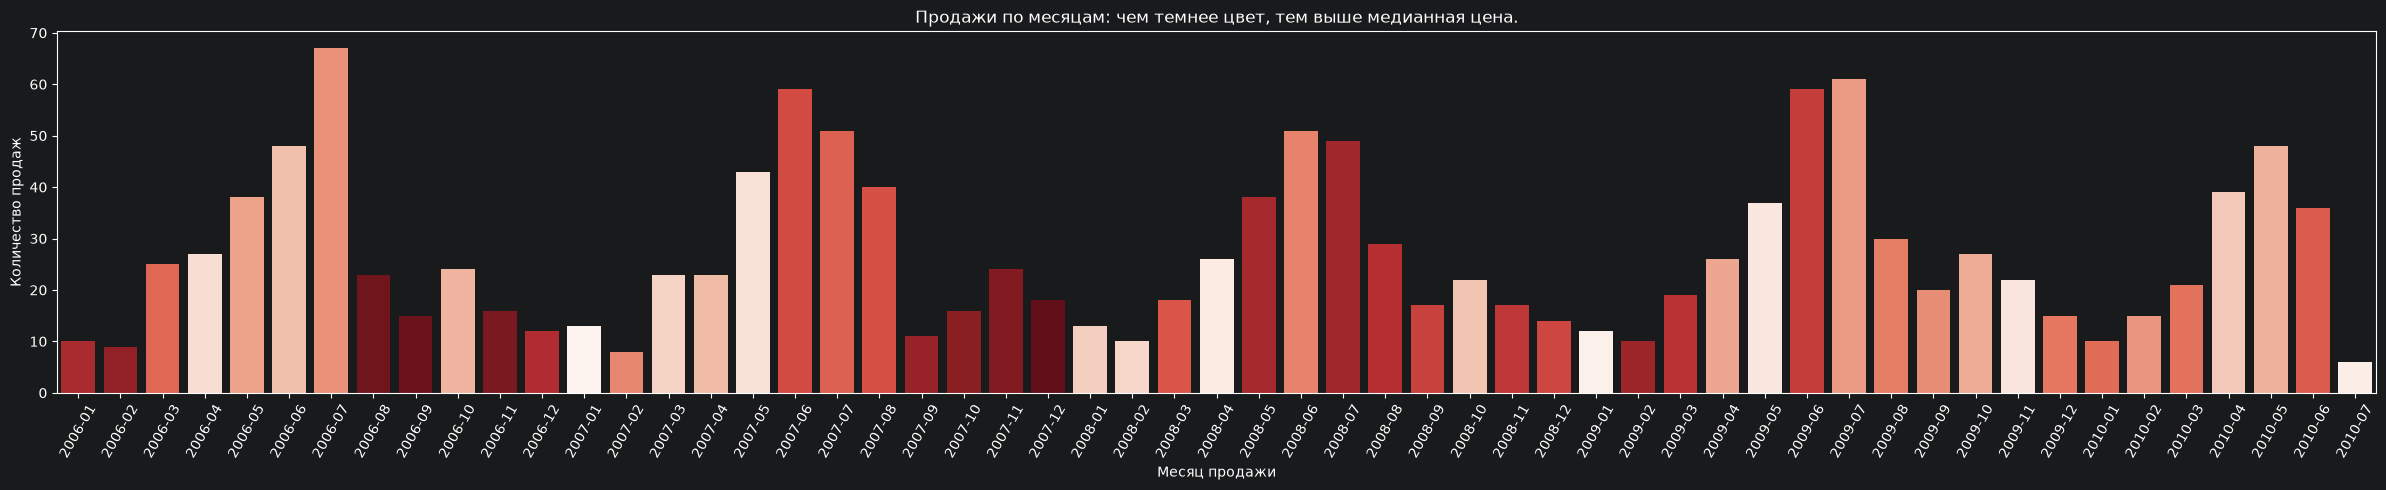

In [118]:
plot_data = train.copy()
plot_data['MoYrSold'] = plot_data['YrSold'].astype(str) + '-' + train['MoSold'].astype(str).str.zfill(2)

price_order = plot_data.groupby('MoYrSold')['SalePrice'].median().sort_values().index

fig, ax = plt.subplots(figsize=(24, 5))
sns.countplot(data=plot_data, x='MoYrSold', order=sorted(plot_data['MoYrSold'].unique()), hue='MoYrSold', hue_order=price_order,palette=sns.color_palette('Reds', n_colors=len(price_order)),legend=False,ax=ax)
ax.set_title('Продажи по месяцам: чем темнее цвет, тем выше медианная цена.')
ax.tick_params(axis='x', labelrotation=60)
ax.set_xlabel('Месяц продажи')
ax.set_ylabel('Количество продаж')
plt.tight_layout()
plt.show()

#### В 2006–2009 годах пик числа продаж приходился на июнь или июль. <br>
#### При объединении всех лет сентябрь лидировал по медианной цене продажи, но при разбивке по годам этот результат повторяется не каждый год.

## Краткий вывод:
_**Цена продажи имеет правостороннюю симметрию. Среди признаков с наиболее высокой связью с ценой выделяются `GrLivArea`(надземная жилая площадь), `2ndFlrSF`(площадь второго этажа) и `OverallQual`(общее качество материалов и отделки). <br>
Медианные цены также заметно различаются по `Neighborhood`(районам) и `KitchenQual`(качество кухни). Часть пропусков отражает отсутствие объекта, например, забора или гаража. Редкие категории, такие как оценки качества бассейна, представлены слишком малым числом домов для уверенного сравнения цен.**_


### Гипотезы для FE:
 -Возраст дома на момент продажи (`YrSold - YearBuilt`). <br>
 -Число лет с последнего ремонта на момент продажи (`YrSold - YearRemodAdd`). <br>
 -Наличие второго этажа (`2ndFlrSF > 0`) и наличие гаража (`GarageArea > 0`). <br>
 -Суммарная надземная жилая и подвальная площадь (`GrLivArea + TotalBsmtSF`). <br>